# Record repair and a frozen push screen: demo

**Artifact** `art_sV0cQ3ef1ZRQ` (evaluation, iteration 4, Step 0) of a study on *algorithm choice* in Qwen3-8B, with Llama-3.1-8B as the replication model. Asked to "implement X", the model writes the same **default mechanism** almost every time: BFS for path search (T1), Dijkstra for shortest paths (T2), a full sort for k-th smallest (T03), a hash map for two-sum (T05). The study asks which knobs move it off that default, and whether temperature is really the "creativity knob". The knobs are temperature and samplers, prompt bans ("do not use X"), novelty instructions, token vetoes, and directions added to the residual stream.

This artifact's `eval.py` recomputes every reported number from labelled rows of 11 earlier experiments. It runs on CPU only and generates no model text. It also **freezes the push-movability screen** `screen.json` (sha256 `d6a2ca97…`), which records the tasks a random activation direction can push off the default and checks whether those are the tasks where a prompt ban works.

**What this notebook runs.** `eval.py` has 14 stages, and most of them need the 11 dependency artifacts on the run server. This demo replays, with the original code, the three stages that produce the frozen screen:

1. **rows**: the labelled programs of the 154 knob cells the screen reads, rebuilt from `mini_demo_data.json`;
2. **knob** (review item 0a): one row per artifact × task × arm × dial. Each row has its pass rate, off-default share, correct-only rarefied Hill-1 (H1r25) with 90% bootstrap CIs, Good's coverage, pass cost against the cell's own twin (Newcombe 95% CI) and escape/qualify flags;
3. **screen** (review item 0i): the stdlib screen rule, which writes `screen.json`, its sha256 and the unhashed extras (Fisher p, power notes, per-engine counts).

At the original bootstrap sizes, the recomputed knob rows match the published `tables/knob_table.csv` cell for cell, and `screen.json` matches the frozen file byte for byte.

| term | meaning |
|---|---|
| cell | one artifact × task × arm × dial, e.g. exp17 · T03 · `RAND9001_a1.0` (a norm-matched random direction added at α = 1) |
| twin | the cell's own neutral control on the same engine and precision (`hf_twin`, `NEUTRAL`, `twin`, `baseline`) |
| off-default share | 1 − n_default / n_attempted |
| escape | offdef(direction) − offdef(twin) ≥ 0.20 **and** pass(direction) ≥ 0.8 × pass(twin) |
| E_t(α), movable | share of a task's random directions that escape at α; the task is movable iff E_t(α) > 0 for some α ≤ 2 |
| catalogue-only ban avoidance | share of attempted programs under the modal "do not use X" ban that land on *another catalogue* mechanism |
| screen rule | movable(t) ⇒ catalogue-only ban avoidance(t) ≥ 0.5 |
| H1r25 | exp(Shannon entropy) over the mechanisms of *correct* programs, rarefied to 25 programs (1 = a single mechanism) |
| pass cost | 100 × (pass_twin − pass_cell), in points |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install
_pip('loguru==0.7.3')

# numpy, pandas, scipy, matplotlib, pyarrow — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pyarrow==18.1.0')

In [2]:
from __future__ import annotations

# eval.py
import argparse
import json
import resource
import sys
import time
from pathlib import Path

from loguru import logger

# src/stages.py, src/paths.py, src/labels.py, src/rows.py, src/stats.py, src/knob.py, src/screen.py, screen_rule.py
import hashlib
import importlib.util
import itertools
import math
import multiprocessing as mp
import os
import re
from collections import Counter
from concurrent.futures import ProcessPoolExecutor
from functools import lru_cache
from typing import Any, Iterable, Iterator, Sequence

import numpy as np
import pandas as pd
from scipy import stats as sps

# notebook additions: a namespace for the screen rule, and the figures
import types

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-4/evaluation-3/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

# The URL can still serve an older demo file until this notebook's data is pushed; only a copy that carries this
# notebook's data version is used, otherwise the local mini_demo_data.json is read.
DEMO_DATA_VERSION = "rows-knob-screen-154-cells-v1"

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            remote = json.loads(response.read().decode())
        if isinstance(remote, dict) and remote.get("metadata", {}).get("demo_data_version") == DEMO_DATA_VERSION:
            return remote
        print("GitHub data is an older version of mini_demo_data.json, using the local copy")
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples = data["datasets"][0]["examples"]
print(data["metadata"]["title"])
print(f"dataset '{data['datasets'][0]['dataset']}': {len(examples)} task examples, "
      f"{sum(len(e['knob_cells']) for e in examples)} knob cells, "
      f"{sum(pt['count'] for e in examples for c in e['knob_cells'] for pt in c['row_patterns'])} labelled rows")

GitHub data is an older version of mini_demo_data.json, using the local copy
Record repair and a frozen push screen: demo subset (rows -> knob -> screen)
dataset 'push_screen': 14 task examples, 154 knob cells, 8800 labelled rows


## Configuration

The run-size knobs are the rarefaction and bootstrap sizes of `src/stats.py` and the worker count of `src/knob.py`. The original values are in the comments.

- **H1r25 and its CIs need the original sizes to match the published table.** The H1r25 point value is the mean over `N_RAREFY` seeded subsamples, so a smaller `N_RAREFY` gives a noisier number than the published one. The same holds for the CI sizes.
- **Every other knob column, and the whole screen, is exact at any size.** That includes the counts, shares, coverage and the pass cost against the twin. The screen uses only counts, so `screen.json` and its sha256 reproduce at any setting.

`DEPTH`, `DEPTH_LOW` and `MASTER_SEED` define the statistics themselves and are not run-size knobs. The stats cell below reads all six constants from here, in place of the constants at the top of the original module.

In [5]:
# --- run-size knobs: scale these ------------------------------------------------------------------------------------
N_RAREFY = 1000         # rarefaction subsamples behind each H1r25 point value      (original: 1000)
N_BOOT = 1000           # bootstrap replicates per 90% CI, template and iid          (original: 1000)
N_BOOT_RAREFY = 200     # rarefaction subsamples inside each bootstrap replicate     (original: 200)
N_WORKERS = 2           # worker processes for the knob cells; Colab has 2 vCPUs   (original: 5)
MEMORY_LIMIT_GB = 18.0  # eval.py's RLIMIT_AS cap on the process                     (original: 18.0)

# --- definitions of the statistics (fixed by the plan, not run-size knobs) -----------------------------------------
MASTER_SEED = 20261021  # each cell's seed is int(sha256('20261021|' + cell_id)[:8], 16)
DEPTH = 25              # rarefaction depth of H1r25, in correct programs
DEPTH_LOW = 10          # depth of H1r10, reported for cells with fewer than 25 correct programs

## `eval.py`: entry point, logging, memory cap and output folders

`eval.py` runs a list of stages in order. Each stage reads the previous stages' outputs from `data/`, `results/` and `tables/`. The cell below is its top level, plus the output-folder block of `src/stages.py`, with three notebook changes:

1. outputs go to `./demo_outputs/` instead of the artifact folder;
2. `--stages` is a function argument instead of an `argparse` flag;
3. the stage functions are looked up in this notebook (`globals()`) instead of the `src.stages` module.

The demo runs `main("rows")`, `main("knob")` and `main("screen")`. The other stages need inputs that are not shipped here, so they are not run:

| stage | why it is not run |
|---|---|
| `inventory` | hashes the 11 dependency folders |
| `judges`, `other` (0d 'other' audit) | read the dependency files and the judge cache |
| `route` (0b), `llama` (0c) | read the dependency files |
| `figures` (0e) | needs exp9's 0.95 GB of activation states |
| `rigor` (0g), `wording` (0h), `rivals` (0j), `audit` | need the full 1,120-cell table and the dependency files |
| `outputs` | assembles every section |

The results of those stages are in the artifact's `results/`, `tables/` and `full_eval_out.json`.

In [6]:
# eval.py — WS was the artifact folder (Path(__file__).resolve().parent); in the notebook outputs go to ./demo_outputs
WS = Path.cwd() / "demo_outputs"
WS.mkdir(exist_ok=True)

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(WS / "logs" / "eval.log", rotation="30 MB", level="DEBUG")

STAGES = ["inventory", "rows", "judges", "knob", "screen", "route", "llama", "other", "figures", "rigor", "wording", "rivals",
          "audit", "outputs"]


def _limit_memory(gb: float = MEMORY_LIMIT_GB) -> None:
    try:
        resource.setrlimit(resource.RLIMIT_AS, (int(gb * 1024 ** 3), int(gb * 1024 ** 3)))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


@logger.catch(reraise=True)
def main(stages_arg: str = "all") -> None:
    # notebook: --stages arrives as an argument instead of through argparse
    stages = STAGES if stages_arg == "all" else [s.strip() for s in stages_arg.split(",")]
    _limit_memory()
    for st in stages:
        t0 = time.time()
        logger.info(f"=== stage {st} ===")
        globals()[f"stage_{st}"]()  # notebook: the stage functions are defined below (eval.py: getattr(S, f"stage_{st}"))
        logger.info(f"=== stage {st} done in {time.time() - t0:.1f}s ===")


# src/stages.py — each stage reads earlier stages' outputs from data/ and results/
DATA = WS / "data"
RES = WS / "results"
TAB = WS / "tables"
for _d in (DATA, RES, TAB, WS / "figures", WS / "audit"):
    _d.mkdir(exist_ok=True)

## `src/paths.py`: the 11 dependency artifacts and the citation convention

Every number in the artifact cites its source as `<artifact_id>:<relative path>`, never an absolute path. `ARTIFACTS` maps each dependency artifact id to its short experiment name. The experiments this demo touches:

| experiment | knob cells used in the demo |
|---|---|
| exp13 | random directions on the HF bf16 engine, modal bans |
| exp17 | random directions at α = 1 and 2, HF with FP8 linears |
| exp9 | single-name bans on T1 and T2 |

`root()` and `p()` resolve a dependency folder on the run server. They are kept as written, but the notebook never calls them: every input comes from `data`.

In [7]:
# src/paths.py — artifact-id -> workspace-root mapping for the 11 declared dependencies (read-only inputs).
# Roots come from AII_ITER1/2/3 or the unpublished paths.local.json on the run server, else from published sibling
# folders under AII_DEPS_DIR. Every output cites '<artifact_id>:<relative path>' and never an absolute path.


def _local_roots() -> dict[str, str]:
    """Machine-specific roots live in paths.local.json (not published); environment variables take precedence."""
    f = WS / "paths.local.json"
    return json.loads(f.read_text()) if f.exists() else {}


_DEFAULT_ROOTS = _local_roots()

# artifact id -> (root env var, workspace folder, short experiment name)
ARTIFACTS: dict[str, tuple[str, str, str]] = {
    "art_U5UKkFrOgSsE": ("AII_ITER1", "gen_art_experiment_4", "exp4"),
    "art_UoCVh2Qe5RZ0": ("AII_ITER1", "gen_art_experiment_6", "exp6"),
    "art_6zBfl3kDjeiP": ("AII_ITER2", "gen_art_experiment_7", "exp7"),
    "art_IVZc3TWCeE9f": ("AII_ITER2", "gen_art_experiment_9", "exp9"),
    "art_0ndRfWKBWclR": ("AII_ITER2", "gen_art_experiment_11", "exp11"),
    "art_1AYTO1Epb_7t": ("AII_ITER3", "gen_art_experiment_13", "exp13"),
    "art_WiY4wqHLb9Gy": ("AII_ITER3", "gen_art_experiment_14", "exp14"),
    "art_Q-qh-9HhPoWo": ("AII_ITER3", "gen_art_experiment_15", "exp15"),
    "art__5akZ9W9iZM4": ("AII_ITER3", "gen_art_experiment_16", "exp16"),
    "art_pVlCZ272hDV7": ("AII_ITER3", "gen_art_experiment_17", "exp17"),
    "art_ccAbfJVcv0LO": ("AII_ITER3", "gen_art_experiment_18", "exp18"),
}
BY_EXP = {v[2]: k for k, v in ARTIFACTS.items()}


def root(aid: str) -> Path:
    """Dependency workspace: AII_ITERn (or the unpublished paths.local.json) on the run server; otherwise the
    published sibling folder under AII_DEPS_DIR (default: this workspace's parent), named by artifact id or by the
    original workspace folder name."""
    env, folder, _ = ARTIFACTS[aid]
    base = os.environ.get(env) or _DEFAULT_ROOTS.get(env)
    if base:
        return Path(base) / folder
    deps = Path(os.environ.get("AII_DEPS_DIR") or WS.parent)
    for cand in (deps / aid, deps / folder, *sorted(deps.glob(f"*{aid}*"))):
        if cand.is_dir():
            return cand
    raise FileNotFoundError(f"dependency {aid} ({folder}) not found under {deps}; set AII_DEPS_DIR or {env}")


def p(exp_or_aid: str, rel: str) -> Path:
    """Absolute path of a dependency file, addressed by 'exp13' or by artifact id."""
    aid = BY_EXP.get(exp_or_aid, exp_or_aid)
    return root(aid) / rel


def cite(exp_or_aid: str, rel: str) -> str:
    aid = BY_EXP.get(exp_or_aid, exp_or_aid)
    return f"{aid}:{rel}"


def exp_name(aid: str) -> str:
    return ARTIFACTS[aid][2]


print({aid: v[2] for aid, v in ARTIFACTS.items()})

{'art_U5UKkFrOgSsE': 'exp4', 'art_UoCVh2Qe5RZ0': 'exp6', 'art_6zBfl3kDjeiP': 'exp7', 'art_IVZc3TWCeE9f': 'exp9', 'art_0ndRfWKBWclR': 'exp11', 'art_1AYTO1Epb_7t': 'exp13', 'art_WiY4wqHLb9Gy': 'exp14', 'art_Q-qh-9HhPoWo': 'exp15', 'art__5akZ9W9iZM4': 'exp16', 'art_pVlCZ272hDV7': 'exp17', 'art_ccAbfJVcv0LO': 'exp18'}


## `src/labels.py` (step G1): mechanism catalogues, aliases and the model's defaults

Each task has a **catalogue** of known mechanisms. For the 12 bench tasks it comes from exp11's `bench/<task>/spec.json`, for example T03 *k-th smallest*: full sort, size-k heap, heapify-pop, quickselect, median of medians, counting sort. T1 (path search) and T2 (shortest path) have fixed lists. `QWEN_DEFAULT` is the mechanism Qwen3-8B writes almost every time: BFS on T1, Dijkstra on T2, a full sort on T03, a hash map on T05.

Frozen labels are used as recorded, and only old spellings are aliased. Labels such as `no_code`, `unparseable` and `unresolved` do not count as an attempted program.

One notebook change: `spec()` reads the `catalogue` field of each bench spec from `mini_demo_data.json` instead of the exp11 folder.

In [8]:
# src/labels.py — STEP G1: label normalisation. Frozen labels are used as recorded; only spellings are aliased.
# Catalogues: bench tasks from exp11 bench/<task>/spec.json; T1 = exp9's 7-mode analysis catalogue (plus
# iteration-1's dijkstra_unit, kept verbatim and flagged); T2 = dijkstra, bf_spfa, bidijkstra, floyd, dial.

BENCH_DIRS = {
    "T03": "T03_kth_smallest", "T04": "T04_substring_search", "T05": "T05_two_sum", "T06": "T06_find_duplicate",
    "T08": "T08_fibonacci", "T10": "T10_connected_components", "T11": "T11_longest_increasing_subsequence",
    "T13": "T13_merge_intervals", "T14": "T14_top_k_frequent", "R1": "R1_non_overlapping_intervals",
    "R2": "R2_cycle_detection", "R3": "R3_topological_order", "R6": "R6_first_last_position",
}
BENCH12 = ["T03", "T04", "T05", "T06", "T08", "T10", "T11", "T13", "T14", "R1", "R3", "R6"]
PATH_TASKS = ["T1", "T2"]
QWEN14 = BENCH12 + PATH_TASKS

T1_CATALOGUE = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "idastar", "dijkstra_unit"]
T2_CATALOGUE = ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]

# iteration-1/2 spellings -> canonical
ALIASES = {
    "bellman_ford_spfa": "bf_spfa", "bidirectional_bfs": "bibfs", "floyd_warshall": "floyd",
    "bidirectional_dijkstra": "bidijkstra", "astar_greedy": "astar", "astar_gbfs": "astar",
}
# labels that are not an attempted program (no code / unparseable / unresolved)
NOT_ATTEMPTED = {"invalid", "no_code", "unparseable", "disputed", "unresolved", "extraction_failed", "", "none", "None"}
NON_CATALOGUE_KEEP = {"other", "builtin", "unknown", "invalid", "no_code", "unparseable", "disputed", "unresolved"}

QWEN_DEFAULT = {
    "T03": "full_sort", "T04": "naive", "T05": "hash_map", "T06": "hash_set", "T08": "iteration", "T10": "union_find",
    "T11": "quadratic_dp", "T13": "sort_sweep", "T14": "sort_by_count", "R1": "greedy_end", "R3": "kahn",
    "R6": "binary_search", "T1": "bfs", "T2": "dijkstra",
}


@lru_cache(maxsize=None)
def spec(task: str) -> dict:
    # notebook: the 'catalogue' field of exp11 bench/<task>/spec.json ships in mini_demo_data.json
    # (original: return json.loads(p("exp11", f"bench/{BENCH_DIRS[task]}/spec.json").read_text()))
    return data["metadata"]["bench_specs"][task]


@lru_cache(maxsize=None)
def catalogue(task: str) -> tuple[str, ...]:
    if task == "T1":
        return tuple(T1_CATALOGUE)
    if task == "T2":
        return tuple(T2_CATALOGUE)
    return tuple(c["mode"] for c in spec(task)["catalogue"])


def catalogue_descriptions(task: str) -> dict[str, str]:
    if task in PATH_TASKS:
        return {m: m for m in catalogue(task)}
    return {c["mode"]: f"{c['display_name']}: {c['mechanism']}" for c in spec(task)["catalogue"]}


def norm_task(t: str) -> str:
    t = str(t)
    return {"t1": "T1", "t2": "T2"}.get(t, t)


def norm_label(lab: object) -> str:
    s = "no_code" if lab is None else str(lab).strip()
    return ALIASES.get(s, s)


def is_catalogue(task: str, lab: str) -> bool:
    try:
        return lab in catalogue(task)
    except KeyError:
        return False


def attempted(lab: str) -> bool:
    return lab not in NOT_ATTEMPTED


@lru_cache(maxsize=None)
def llama_defaults() -> dict[str, str]:
    out = {}
    for line in p("exp15", "results/c1_events.jsonl").read_text().splitlines():
        if line.strip():
            ev = json.loads(line)
            if ev["event_type"] == "modal":
                out[ev["task"]] = ev["banned"]
    return out


def default_of(task: str, model: str = "qwen") -> str | None:
    if "llama" in model.lower():
        return llama_defaults().get(task)
    return QWEN_DEFAULT.get(task)


for t in QWEN14:
    print(f"{t:>4}  default {QWEN_DEFAULT[t]:<14} catalogue {', '.join(catalogue(t))}")

 T03  default full_sort      catalogue full_sort, size_k_heap, heapify_pop, quickselect, median_of_medians, counting_sort
 T04  default naive          catalogue naive, kmp, rabin_karp, z_algorithm, bmh, builtin
 T05  default hash_map       catalogue hash_map, sort_two_pointers, brute_force, sort_binary_search
 T06  default hash_set       catalogue hash_set, sort_adjacent, floyd, value_binary_search, index_marking
 T08  default iteration      catalogue iteration, memo_recursion, matrix_power, fast_doubling
 T10  default union_find     catalogue bfs, dfs, union_find, label_propagation
 T11  default quadratic_dp   catalogue quadratic_dp, patience_bisect, fenwick
 T13  default sort_sweep     catalogue sort_sweep, interval_tree, union_find
 T14  default sort_by_count  catalogue sort_by_count, heap, bucket_sort, quickselect_counts
  R1  default greedy_end     catalogue greedy_end, dp_bisect, memo_recursion, dag_longest_path
  R3  default kahn           catalogue kahn, dfs_postorder, source_r

## `src/stats.py`: the shared statistics

The original module is unit-tested on hand-computed toy cells in the artifact's `tests/test_stats.py`.

- **`rarefied_hill1`**: Hill-1 = exp(Shannon entropy) of a mechanism composition. It is averaged over `N_RAREFY` subsamples of exactly `DEPTH` = 25 programs, drawn without replacement (multivariate hypergeometric). This makes cells with different numbers of correct programs comparable.
- **`h1r_cell`**: one cell's H1r25 on its *correct* programs, with Good's coverage and two 90% percentile intervals:
  - an iid program bootstrap;
  - a template-cluster bootstrap, which replaces the iid interval when all five prompt wordings W1–W5 have at least 5 correct programs.

  Each cell's seed comes from `MASTER_SEED` and the cell id, so results do not depend on the order cells are processed in.
- **`newcombe_diff`**: the pass-rate difference to the twin, with the Newcombe hybrid-score 95% interval (the "pass cost").
- **`fisher_2x2`, `balanced_accuracy`, `upper_bound_zero_of_k`**: the screen's descriptive statistics.

`spearman_perm`, `holm`, `jackknife_ci`, `cohen_kappa`, `kappa_boot_ci` and `js_div2` serve stages outside this demo (rivals, route, 'other' audit). They are kept as written.

In [9]:
# src/stats.py — shared statistics (Section 1 of the plan). Unit-tested in tests/test_stats.py on hand-computed toy cells.
# notebook: MASTER_SEED, DEPTH, DEPTH_LOW, N_RAREFY, N_BOOT and N_BOOT_RAREFY are set in the configuration cell


def cell_seed(cell_id: str) -> int:
    return int(hashlib.sha256(f"{MASTER_SEED}|{cell_id}".encode()).hexdigest()[:8], 16)


def hill1_counts(x: np.ndarray) -> float:
    x = np.asarray(x, float)
    x = x[x > 0]
    if x.sum() <= 0:
        return float("nan")
    q = x / x.sum()
    return float(math.exp(-(q * np.log(q)).sum()))


def _hill1_rows(draws: np.ndarray, depth: int) -> np.ndarray:
    q = draws / depth
    with np.errstate(divide="ignore", invalid="ignore"):
        h = np.where(q > 0, q * np.log(np.where(q > 0, q, 1.0)), 0.0).sum(axis=1)
    return np.exp(-h)


def rarefied_hill1(counts: Sequence[int], depth: int, n_draws: int, rng: np.random.Generator) -> float:
    c = np.asarray([int(v) for v in counts if int(v) > 0], np.int64)
    if c.sum() < depth or len(c) == 0:
        return float("nan")
    if len(c) == 1:
        return 1.0
    if c.sum() == depth:
        return hill1_counts(c)
    d = rng.multivariate_hypergeometric(c, depth, size=n_draws, method="marginals")
    return float(_hill1_rows(d, depth).mean())


def goods_coverage(counts: Sequence[int]) -> float:
    c = np.asarray([v for v in counts if v > 0])
    n = c.sum()
    if n == 0:
        return float("nan")
    f1 = int((c == 1).sum())
    return float(1 - f1 / n)


def expected_coverage_at(counts: Sequence[int], m: int) -> float:
    """Expected sample coverage of a size-m subsample (interpolation, Chao & Jost 2012 eq. 4a)."""
    c = np.asarray([v for v in counts if v > 0], float)
    n = int(c.sum())
    if m >= n:
        return goods_coverage(c)
    tot = 0.0
    for xi in c:
        if n - xi >= m:
            # C(n - xi, m) / C(n - 1, m)
            tot += (xi / n) * math.exp(math.lgamma(n - xi + 1) - math.lgamma(n - xi - m + 1)
                                       - math.lgamma(n) + math.lgamma(n - m))
    return float(1 - tot)


def coverage_standardised_hill1(counts: Sequence[int], target_cov: float, rng: np.random.Generator,
                                n_draws: int = 400) -> tuple[float, int]:
    """Hill-1 rarefied to the size m whose expected coverage first reaches target_cov (interpolation only)."""
    c = [int(v) for v in counts if v > 0]
    n = sum(c)
    if n == 0 or not np.isfinite(target_cov):
        return float("nan"), 0
    m_star = n
    for m in range(1, n + 1):
        if expected_coverage_at(c, m) >= target_cov - 1e-12:
            m_star = m
            break
    return rarefied_hill1(c, m_star, n_draws, rng), m_star


def h1r_cell(correct_labels: Sequence[str], templates: Sequence[str] | None, cell_id: str, depth: int = DEPTH,
             drop: Iterable[str] = (), n_boot: int = N_BOOT, n_boot_rarefy: int = N_BOOT_RAREFY,
             with_ci: bool = True) -> dict:
    """Correct-only rarefied Hill-1 for one cell; percentile CIs (template-cluster when eligible, and iid)."""
    drop = set(drop)
    keep = [i for i, l in enumerate(correct_labels) if l not in drop]
    labs = [correct_labels[i] for i in keep]
    tpls = [templates[i] for i in keep] if templates is not None else None
    cats = sorted(set(labs))
    idx = {c: i for i, c in enumerate(cats)}
    counts = np.zeros(len(cats), np.int64)
    for l in labs:
        counts[idx[l]] += 1
    n_c = int(counts.sum())
    rng = np.random.default_rng(cell_seed(f"{cell_id}|d{depth}|{'-'.join(sorted(drop))}"))
    out = {"n_c": n_c, "S_obs": int((counts > 0).sum()), "coverage": goods_coverage(counts),
           "value": rarefied_hill1(counts, depth, N_RAREFY, rng), "ci90": [float("nan")] * 2,
           "ci90_iid": [float("nan")] * 2, "ci_unit": None}
    if not with_ci or n_c < depth or len(cats) <= 1:
        if n_c >= depth and len(cats) == 1:
            out["ci90"] = [1.0, 1.0]
            out["ci90_iid"] = [1.0, 1.0]
            out["ci_unit"] = "degenerate"
        return out
    # iid program bootstrap
    probs = counts / n_c
    vals = np.full(n_boot, np.nan)
    for b in range(n_boot):
        cb = rng.multinomial(n_c, probs)
        vals[b] = rarefied_hill1(cb, depth, n_boot_rarefy, rng)
    out["ci90_iid"] = [float(np.nanquantile(vals, 0.05)), float(np.nanquantile(vals, 0.95))]
    out["ci90"] = list(out["ci90_iid"])
    out["ci_unit"] = "program"
    if tpls is not None:
        by_t: dict[str, np.ndarray] = {}
        for l, t in zip(labs, tpls):
            by_t.setdefault(str(t), np.zeros(len(cats), np.int64))[idx[l]] += 1
        tkeys = sorted(by_t)
        if len(tkeys) == 5 and all(by_t[t].sum() >= 5 for t in tkeys):
            mat = np.stack([by_t[t] for t in tkeys])
            tv = np.full(n_boot, np.nan)
            for b in range(n_boot):
                pick = rng.integers(0, len(tkeys), len(tkeys))
                tv[b] = rarefied_hill1(mat[pick].sum(0), depth, n_boot_rarefy, rng)
            if np.isfinite(tv).sum() > 0.5 * n_boot:
                out["ci90"] = [float(np.nanquantile(tv, 0.05)), float(np.nanquantile(tv, 0.95))]
                out["ci_unit"] = "template(5 clusters; few-cluster)"
    return out


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return float("nan"), float("nan")
    ph = k / n
    den = 1 + z * z / n
    c = (ph + z * z / (2 * n)) / den
    h = z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / den
    return max(0.0, c - h), min(1.0, c + h)


def newcombe_diff(k1: int, n1: int, k2: int, n2: int) -> tuple[float, float, float]:
    """p1 - p2 with the Newcombe (1998, method 10) hybrid-score 95% interval."""
    if n1 <= 0 or n2 <= 0:
        return float("nan"), float("nan"), float("nan")
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return d, d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)


def poisson_binomial_sf(k: int, probs: Sequence[float]) -> float:
    """P(X >= k) for X = sum of independent Bernoulli(p_i), by dynamic programming."""
    dist = np.zeros(len(probs) + 1)
    dist[0] = 1.0
    for pi in probs:
        dist[1:] = dist[1:] * (1 - pi) + dist[:-1] * pi
        dist[0] *= (1 - pi)
    return float(dist[k:].sum())


def binom_sf(k: int, n: int, p0: float) -> float:
    return float(sps.binom.sf(k - 1, n, p0))


def _rank(a: np.ndarray) -> np.ndarray:
    return sps.rankdata(a)


def spearman_perm(x: Sequence[float], y: Sequence[float], n_perm: int = 1_000_000, seed: int = MASTER_SEED) -> dict:
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    n = len(x)
    if n < 3 or np.all(x == x[0]) or np.all(y == y[0]):
        return {"rho": float("nan"), "p_perm": float("nan"), "n": n, "method": "undefined"}
    rx, ry = _rank(x), _rank(y)
    rx = (rx - rx.mean()) / np.sqrt(((rx - rx.mean()) ** 2).sum())
    ry = (ry - ry.mean()) / np.sqrt(((ry - ry.mean()) ** 2).sum())
    rho = float((rx * ry).sum())
    if n <= 9:
        perms = np.array(list(itertools.permutations(range(n))))
        null = (rx[None, :] * ry[perms]).sum(1)
        method = f"exact enumeration ({len(perms)} permutations)"
    else:
        rng = np.random.default_rng(seed)
        null = np.empty(n_perm)
        chunk = 100_000
        for s in range(0, n_perm, chunk):
            m = min(chunk, n_perm - s)
            idx = np.argsort(rng.random((m, n)), axis=1)
            null[s:s + m] = (rx[None, :] * ry[idx]).sum(1)
        method = f"Monte Carlo permutation ({n_perm} draws)"
    p = float((np.abs(null) >= abs(rho) - 1e-12).mean())
    tau = sps.kendalltau(x, y)
    return {"rho": rho, "p_perm": p, "n": n, "method": method, "kendall_tau_b": float(tau.statistic),
            "kendall_p": float(tau.pvalue)}


def holm(pvals: Sequence[float]) -> list[float]:
    p = np.asarray(pvals, float)
    out = np.full(len(p), np.nan)
    ok = np.where(np.isfinite(p))[0]
    order = ok[np.argsort(p[ok])]
    m = len(order)
    run = 0.0
    for i, j in enumerate(order):
        run = max(run, min(1.0, (m - i) * p[j]))
        out[j] = run
    return out.tolist()


def jackknife_ci(theta: float, jack_vals: Sequence[float], level: float = 0.95) -> list[float]:
    j = np.asarray(jack_vals, float)
    n = len(j)
    if n < 3:
        return [float("nan"), float("nan")]
    se = math.sqrt((n - 1) / n * ((j - j.mean()) ** 2).sum())
    tq = sps.t.ppf(0.5 + level / 2, n - 1)
    return [theta - tq * se, theta + tq * se]


def cohen_kappa(a: Sequence[str], b: Sequence[str]) -> float:
    a, b = list(a), list(b)
    n = len(a)
    if n == 0:
        return float("nan")
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[k] * cb.get(k, 0) for k in ca) / (n * n)
    return float((po - pe) / (1 - pe)) if pe < 1 else float("nan")


def kappa_boot_ci(a: Sequence[str], b: Sequence[str], n_boot: int = 2000, seed: int = MASTER_SEED) -> list[float]:
    a, b = list(a), list(b)
    n = len(a)
    if n < 3:
        return [float("nan"), float("nan")]
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        ix = rng.integers(0, n, n)
        vals.append(cohen_kappa([a[i] for i in ix], [b[i] for i in ix]))
    v = np.asarray(vals, float)
    v = v[np.isfinite(v)]
    return [float(np.quantile(v, 0.025)), float(np.quantile(v, 0.975))] if len(v) else [float("nan")] * 2


def balanced_accuracy(pred: Sequence[int], truth: Sequence[int]) -> float:
    pred, truth = np.asarray(pred), np.asarray(truth)
    pos, neg = truth == 1, truth == 0
    if pos.sum() == 0 or neg.sum() == 0:
        return float("nan")
    return float(0.5 * ((pred[pos] == 1).mean() + (pred[neg] == 0).mean()))


def fisher_2x2(pred: Sequence[int], truth: Sequence[int], alternative: str = "two-sided") -> dict:
    pred, truth = np.asarray(pred), np.asarray(truth)
    tab = [[int(((pred == 1) & (truth == 1)).sum()), int(((pred == 1) & (truth == 0)).sum())],
           [int(((pred == 0) & (truth == 1)).sum()), int(((pred == 0) & (truth == 0)).sum())]]
    res = sps.fisher_exact(tab, alternative=alternative)
    return {"table": tab, "p": float(res.pvalue), "alternative": alternative}


def js_div2(p: np.ndarray, q: np.ndarray) -> float:
    """Base-2 Jensen-Shannon divergence (exp16 convention)."""
    p = np.asarray(p, float) / np.sum(p)
    q = np.asarray(q, float) / np.sum(q)
    m = 0.5 * (p + q)

    def kl(a, b):
        mask = a > 0
        return float((a[mask] * np.log2(a[mask] / b[mask])).sum())

    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def upper_bound_zero_of_k(k: int, level: float = 0.90) -> float:
    """One-sided upper bound on a per-direction escape probability when 0 of k escape."""
    return float(1 - (1 - level) ** (1 / k)) if k > 0 else float("nan")


# toy check: three mechanisms at 20/20/10 correct programs, rarefied to 25
_toy = h1r_cell(["a"] * 20 + ["b"] * 20 + ["c"] * 10, None, "toy")
print(f"toy cell: H1r25 = {_toy['value']:.3f} (unrarefied Hill-1 {hill1_counts([20, 20, 10]):.3f}), "
      f"coverage {_toy['coverage']:.2f}, 90% CI {np.round(_toy['ci90'], 3).tolist()}")

toy cell: H1r25 = 2.813 (unrarefied Hill-1 2.872), coverage 1.00, 90% CI [2.518, 2.912]


## Stage `rows` (step G2): the labelled programs

In the full run, `src/rows.py` reads the labelled rows of 10 dependency artifacts (65,433 programs) into one table with one row per generated program. `_row()` normalises each record:

- aliases the label;
- marks whether the label is in the task's catalogue;
- marks whether it is the model's default;
- marks whether it is an attempted program;
- records whether the program passed the hidden tests.

`mini_demo_data.json` holds the 8,800 rows of the 154 knob cells the screen reads. They are stored as **row patterns**: identical rows collapsed into one entry with a count, kept in their original order so tie-breaking is reproduced exactly. The 154 cells are:

- the 108 random-direction cells;
- the 18 twins of those cells;
- the 14 modal-ban cells;
- the 14 twins of the ban cells.

`build_rows()` is the only function rewritten for the notebook. Instead of the ten loaders it expands the patterns, sends every row through the original `_row()`, and checks that the flags `_row()` recomputes from the label and the catalogue agree with the recorded ones.

In [10]:
# src/rows.py — STEP G2: unified row table (rows.parquet) from the labelled rows of the declared dependencies.
# One row per labelled program. Arm names are each artifact's own: exp13 condition, exp17 c2d.json arm keys,
# exp9 condition (the other experiments' arms are not in this demo).

FIELDS = ["artifact_id", "src_file", "model", "engine", "precision", "task", "arm", "dial", "template", "sample_id",
          "label", "label_norm", "is_catalogue", "is_default", "attempted", "passed", "code_sha256", "extra"]


def _b(v: Any) -> bool:
    return v is True or str(v).lower() == "true"


def _row(exp: str, rel: str, r: dict, *, model: str, engine: str, precision: str, task: str, arm: str,
         dial: dict | None = None, template: Any = None, extra: dict | None = None) -> dict:
    task = norm_task(task)
    lab = norm_label(r.get("label"))
    d = default_of(task, model)
    return {"artifact_id": BY_EXP[exp], "src_file": rel, "model": model, "engine": engine, "precision": precision,
            "task": task, "arm": arm, "dial": json.dumps(dial or {}, sort_keys=True),
            "template": str(template if template is not None else r.get("template")),
            "sample_id": str(r.get("sample_id") or r.get("key") or r.get("uid")), "label": str(r.get("label")),
            "label_norm": lab, "is_catalogue": is_catalogue(task, lab), "is_default": bool(d is not None and lab == d),
            "attempted": attempted(lab), "passed": _b(r.get("passed")), "code_sha256": str(r.get("code_sha256") or ""),
            "extra": json.dumps(extra or {}, sort_keys=True)}


QWEN = "Qwen/Qwen3-8B"
LLAMA = "meta-llama/Llama-3.1-8B-Instruct"


def build_rows(out_path: Path) -> pd.DataFrame:
    # notebook: replaces the ten dependency loaders (load_exp17, load_exp13, load_exp9, ...). Each recorded row pattern
    # is expanded `count` times and every row goes through the original _row(). Sample ids, code hashes and raw
    # (pre-alias) labels are not shipped, so label = label_norm here; none of them is read by the knob or screen stage.
    out, recorded = [], []
    for ex in data["datasets"][0]["examples"]:
        for cell in ex["knob_cells"]:
            exp = exp_name(cell["artifact_id"])
            for pat in cell["row_patterns"]:
                for _ in range(pat["count"]):
                    out.append(_row(exp, cell["src_file"], {"label": pat["label_norm"], "passed": pat["passed"]},
                                    model=cell["model"], engine=cell["engine"], precision=cell["precision"],
                                    task=cell["task"], arm=cell["arm"], dial=json.loads(cell["dial"]),
                                    template=pat["template"]))
                    recorded.append([pat["is_catalogue"], pat["is_default"], pat["attempted"]])
    df = pd.DataFrame(out, columns=FIELDS)
    agree = (df[["is_catalogue", "is_default", "attempted"]].to_numpy() == np.array(recorded)).all(axis=0)
    logger.info(f"rows: _row() flags agree with the recorded ones (is_catalogue, is_default, attempted): {agree.tolist()}")
    df.to_parquet(out_path, index=False)
    logger.info(f"rows.parquet: {len(df)} rows -> {out_path.name}")
    return df


# src/stages.py
def stage_rows() -> None:
    build_rows(DATA / "rows.parquet")


main("rows")
rows = pd.read_parquet(DATA / "rows.parquet")
print(rows.groupby(["task", "artifact_id"]).size().unstack(fill_value=0).rename(columns=exp_name).T.to_string())
rows.head()

15:08:28|INFO   |=== stage rows ===


15:08:28|INFO   |rows: _row() flags agree with the recorded ones (is_catalogue, is_default, attempted): [True, True, True]


15:08:28|INFO   |rows.parquet: 8800 rows -> rows.parquet


15:08:28|INFO   |=== stage rows done in 0.2s ===


task          R1   R3   R6   T03  T04  T05  T06  T08    T1  T10  T11  T13  T14    T2
artifact_id                                                                         
exp13        350  350  350   350  350  350  350  350     0  350  350  350  350     0
exp9           0    0    0     0    0    0    0    0   200    0    0    0    0   200
exp17          0    0    0  1000  400  400  400    0  1000    0    0    0    0  1000


,artifact_id,src_file,model,engine,precision,task,arm,dial,template,sample_id,label,label_norm,is_catalogue,is_default,attempted,passed,code_sha256,extra
0,art_1AYTO1Epb_7t,data/samples.jsonl,Qwen/Qwen3-8B,hf,bf16,T03,hf_twin,{},W1,None,full_sort,full_sort,True,True,True,True,,{}
1,art_1AYTO1Epb_7t,data/samples.jsonl,Qwen/Qwen3-8B,hf,bf16,T03,hf_twin,{},W1,None,full_sort,full_sort,True,True,True,True,,{}
2,art_1AYTO1Epb_7t,data/samples.jsonl,Qwen/Qwen3-8B,hf,bf16,T03,hf_twin,{},W1,None,full_sort,full_sort,True,True,True,True,,{}
3,art_1AYTO1Epb_7t,data/samples.jsonl,Qwen/Qwen3-8B,hf,bf16,T03,hf_twin,{},W1,None,full_sort,full_sort,True,True,True,True,,{}
4,art_1AYTO1Epb_7t,data/samples.jsonl,Qwen/Qwen3-8B,hf,bf16,T03,hf_twin,{},W1,None,full_sort,full_sort,True,True,True,True,,{}


## Stage `knob` (review item 0a), part 1: what each arm is and which twin prices it

The knob table has one row per **cell**: artifact × task × arm × dial × precision.

`classify()` turns each experiment's arm name into three fields:

- a **class**: `knob`, `control`, `ablation` or `ceiling`;
- a **family**, such as `activation-random`, `prompt:ban`, `veto` or `decoding`;
- a one-line description.

`ref_of()` finds the cell's **own twin**: the neutral control of the same experiment on the same engine and precision. For example, exp13's HF-engine random directions are priced against `hf_twin`, not against the vLLM `twin`. If no same-precision twin exists, the cell is flagged `cross_precision_ref` or `no_own_twin`.

The `classify()` branches for exp4, exp6, exp14, exp15, exp16 and exp18 do not fire in this demo but are kept as written.

In [11]:
# src/knob.py — (0a) one-statistic knob table: one row per artifact x task x arm x dial cell, priced against its own twin
NONCAT_DROP_MARK = "__noncat__"


# ------------------------------------------------------------------------------------------------ arm dictionary
def classify(exp: str, arm: str, dial: dict) -> tuple[str, str, str]:
    """-> (class, family, one-line description)."""
    a = arm
    if exp == "exp13":
        m = {"twin": ("control", "twin", "neutral twin (vLLM)"), "hf_twin": ("control", "twin", "neutral twin (HF engine)"),
             "sham": ("control", "sham_veto", "sham token veto"), "ban": ("knob", "prompt:ban", "modal 'do not use X' ban"),
             "nonce": ("knob", "prompt:nonce", "nonce ban"), "novelty": ("knob", "prompt:novelty", "novelty instruction"),
             "oneshot": ("knob", "veto", "one-shot token veto"), "persistent": ("knob", "veto", "persistent token veto"),
             "iter1": ("knob", "veto", "iterated veto round 1"), "iter2": ("knob", "veto", "iterated veto round 2"),
             "iter3": ("knob", "veto", "iterated veto round 3"),
             "bandpatch": ("knob", "activation-ban-derived", "ban task-spec states patched into the twin (ban-derived)")}
        if a in m:
            return m[a]
        if a.startswith("rand"):
            return ("knob", "activation-random", "matched-norm isotropic random direction at task-spec states, layers 12-23")
    if exp == "exp17":
        if a == "NEUTRAL":
            return ("control", "twin", "neutral twin (HF, FP8 linears)")
        if a.startswith("BAN"):
            return ("knob", "prompt:ban", "modal ban" + (" (top-up samples)" if "TOPUP" in a else ""))
        if a.startswith("ADD"):
            return ("knob", "activation-structured", "leave-one-task-out prohibition direction added to the twin")
        if a.startswith("RAND"):
            return ("knob", "activation-random", "norm-matched random direction added to the twin")
        if a.startswith("SUB") or a.startswith("HEADS"):
            return ("ablation", "ablation-on-ban", "intervention on the ban (projection / head ablation); not a knob")
        if a.startswith("U7"):
            return ("control", "engine_check", "U7 engine reproduction check")
    if exp == "exp15":
        if a in ("neutral_baseline", "vetofree"):
            return ("control", "twin", "Llama neutral twin" + (" (veto chain pass-1)" if a == "vetofree" else ""))
        if a == "pilot_fp8":
            return ("control", "pilot", "Llama FP8 pilot (no ban)")
        if a in ("nonce", "novelty"):
            return ("knob", f"prompt:{a}", f"{a} prompt (Llama)")
        if a.startswith("rand_"):
            return ("knob", "activation-random", "matched-norm random direction at spec positions, layers 11-21 (Llama)")
        if a.startswith("ban_"):
            return ("knob", "prompt:ban", f"{a.split(':')[0][4:]} ban of {a.split(':')[1]} (Llama)")
        if a.startswith("veto_"):
            return ("knob", "veto", f"{a[5:]} signature-n-gram veto (Llama)")
    if exp == "exp16":
        return ("control", "route_diagnostic", {"a": "full ban", "b": "token-matched neutral twin",
                                                "c": "prompt route (twin condition + ban spec states)",
                                                "d": "direct route (ban condition + twin spec states)",
                                                "K0": "condition span invisible to generated tokens",
                                                "V1": "one-shot veto of the default's n-gram"}.get(a, "route/prefill diagnostic arm"))
    if exp == "exp14":
        kind = a.split(":")[0]
        if kind == "copy":
            return ("control", "copy", "COPY: shown programs of Y, no ban")
        if kind == "baseline":
            return ("control", "twin", "no-exposure baseline")
        if kind in ("named", "unnamed"):
            return ("knob", "prompt:exposure_ban", f"{kind.upper()} exposure ban of the shown algorithm")
        if kind == "veto":
            return ("knob", "veto", "in-context signature veto of the shown algorithm")
        if kind.startswith("W"):
            return ("knob", "prompt:exposure_ban", f"exposure ban, template arm {kind}")
    if exp == "exp18":
        if a == "walk_twin":
            return ("control", "twin", "neutral twin (walk step 0)")
        if a.startswith("walk_step"):
            return ("knob", "veto", "persistent token-walk veto")
        if a == "sham":
            return ("control", "sham_veto", "matched sham veto")
        if a == "fixed_top5":
            return ("knob", "veto", "fixed TOP5 veto")
        if a.startswith("los:"):
            return ("knob", "prompt:list", "leave-one-survivor list ban")
        if a.startswith("two_step:"):
            return ("knob", "prompt:ban", "two-step ban")
        if a.startswith("longform:"):
            return ("knob", "prompt:instruction", "2,000-word 'make a (fully) novel algorithm' instruction")
    if exp == "exp9":
        if a == "baseline":
            return ("control", "twin", "no-ban baseline")
        if a.startswith("single:"):
            return ("knob", "prompt:ban", "single-name ban")
        if a.startswith("los:"):
            return ("knob", "prompt:list", "leave-one-survivor list")
        if a.startswith("multi:"):
            return ("knob", "prompt:list", "multi-name ban list")
    if exp == "exp4":
        if a == "baseline":
            return ("control", "twin", "vLLM baseline")
        if a == "steer:dc":
            if dial.get("c", 0) == 0:
                return ("control", "twin", "HF c=0 hook")
            return ("knob", "activation-structured", "decommitment direction d_dc")
        if a in ("steer:rand1", "steer:rand2"):
            return ("knob", "activation-random", "random direction (iteration 1)")
        if a == "steer:placebo":
            return ("knob", "activation-structured", "variable-name placebo direction")
        if a == "steer:breadth":
            return ("knob", "activation-structured", "breadth direction")
        if a == "steer:dcxfer":
            return ("knob", "activation-structured", "cross-task transferred d_dc")
        if a.startswith("enumerate"):
            return ("knob", "prompt:instruction", "enumeration prompt")
        if a.startswith("ban:"):
            return ("knob", "prompt:ban", "modal ban")
        if a.startswith("mention:"):
            return ("control", "mention_twin", "mention twin")
        if a.startswith("succession"):
            return ("knob", "prompt:ban", "succession ban")
    if exp == "exp6":
        kind, cond = a.split(":", 1)
        if kind == "A0":
            return ("control", "twin", "no-cue baseline T=1.0, pure sampling, thinking off")
        if kind in ("A1", "A6a", "A6b", "A6c", "A6d"):
            return ("knob", "decoding", "temperature x sampler grid" + (" (thinking on)" if dial.get("thinking") else ""))
        if kind == "A2":
            return ("knob", "prompt:seed", f"{cond.replace('seed_', '')} seed")
        if kind == "A3":
            return ("knob", "prompt:instruction", f"creativity instruction {cond}")
        if kind.startswith("A4"):
            return ("ceiling", "generate_then_select", "generate-then-select (ceiling, never ranked)")
    if exp == "exp11":
        return ("control", "pilot", "FP8 pilot (no ban)")
    return ("unclassified", "unclassified", a)


def ref_of(exp: str, arm: str, dial: dict, task: str, precision: str, cells: set) -> tuple[tuple | None, list[str]]:
    """Own-twin reference cell key (exp, task, arm, dial_json, precision) and flags."""
    flags: list[str] = []
    dj = json.dumps({}, sort_keys=True)
    cand = None
    if exp == "exp13":
        hf = arm.startswith("rand") or arm in ("bandpatch", "hf_twin")
        cand = (task, "hf_twin" if hf else "twin", dj)
    elif exp == "exp17":
        cand = (task, "NEUTRAL", dj)
    elif exp == "exp15":
        cand = (task, "vetofree" if arm.startswith("veto_") else "neutral_baseline", dj)
    elif exp == "exp16":
        cand = (task, "b", dj)
    elif exp == "exp14":
        kind = arm.split(":")[0]
        y = arm.split(":", 1)[1] if ":" in arm else None
        cand = (task, "baseline", dj) if kind == "copy" else (task, f"copy:{y}", dj)
    elif exp == "exp18":
        cand = (task, "walk_twin", dj)
    elif exp == "exp9":
        cand = (task, "baseline", dj)
    elif exp == "exp4":
        if arm in ("baseline",) or arm.startswith(("ban:", "mention:", "enumerate", "succession")):
            cand = (task, "baseline", dj)
        else:
            cand = (task, "steer:dc", json.dumps({"c": 0.0, "layer": 18}, sort_keys=True))
    elif exp == "exp6":
        cand = (task, "A0:baseline", json.dumps({"T": 1.0, "sampler": "pure", "thinking": False}, sort_keys=True))
        if dial.get("thinking"):
            flags.append("ref_thinking_off")
    if cand is None:
        return None, flags
    key = (exp,) + cand + (precision,)
    if key in cells:
        return key, flags
    others = [c for c in cells if c[:4] == key[:4]]
    if others:
        flags.append("cross_precision_ref")
        return others[0], flags
    return None, flags + ["no_own_twin"]


print(classify("exp17", "RAND9001_a1.0", {"alpha": 1.0}), "| twin of exp13 T10 rand3:",
      ref_of("exp13", "rand3", {}, "T10", "bf16", {("exp13", "T10", "hf_twin", "{}", "bf16")}))

('knob', 'activation-random', 'norm-matched random direction added to the twin') | twin of exp13 T10 rand3: (('exp13', 'T10', 'hf_twin', '{}', 'bf16'), [])


## Stage `knob`, part 2: every cell priced against its own twin

`build_knob_table()` groups the rows into cells. For each cell it computes:

- **counts and shares**: pass rate, off-default share (1 − default / attempted), catalogue-only avoidance (non-default *catalogue* attempts / attempted) and the 'other' share;
- **diversity of correct programs** (`_cell_job`, run in a process pool):
  - H1r25 with the template-cluster and iid 90% CIs;
  - H1r25 restricted to catalogue mechanisms (`H1r25_cat`);
  - H1r10 for cells below depth 25;
- **price against the twin**: pass cost = 100 × (pass_twin − pass_cell) with the Newcombe 95% CI;
- **flags**:
  - `escape`: off-default share up ≥ 0.20 on the twin, at ≥ 0.8 × the twin's pass rate;
  - `qualify`: H1r25 ≥ 2 within 20 points of pass cost.

Two notebook changes:

- The worker pool uses the `fork` start method. Spawned workers re-import `__main__` and cannot see functions defined in a notebook; forked workers inherit them. This needs Linux, which is what Colab runs.
- `realised_l21_displacement_ratio` is read from exp15's `push_hook_stats.json` for Llama `rand_` cells only, and there are none in this demo.

In [12]:
# src/knob.py (continued)
# ------------------------------------------------------------------------------------------------ cells
def _cell_job(args: tuple) -> dict:
    cid, labels, templates, noncat = args
    prim = h1r_cell(labels, templates, cid, DEPTH)
    cat = h1r_cell(labels, templates, cid + "|cat", DEPTH, drop=noncat, with_ci=False)
    low = h1r_cell(labels, templates, cid, DEPTH_LOW, with_ci=False) if prim["n_c"] < DEPTH else None
    return {"cid": cid, "prim": prim, "cat": cat, "low": low}


def build_knob_table(rows: pd.DataFrame, n_workers: int = N_WORKERS) -> pd.DataFrame:
    rows = rows.copy()
    rows["exp"] = rows.artifact_id.map(exp_name)
    keys = ["exp", "artifact_id", "task", "arm", "dial", "precision"]
    groups = list(rows.groupby(keys, sort=True))
    cellset = {(k[0], k[2], k[3], k[4], k[5]) for k, _ in groups}
    base = []
    jobs = []
    for (exp, aid, task, arm, dial, prec), g in groups:
        cid = f"{aid}|{task}|{arm}|{dial}|{prec}"
        att = g[g.attempted]
        cor = g[g.passed]
        noncat = sorted(set(cor.label_norm[~cor.is_catalogue]))
        jobs.append((cid, cor.label_norm.tolist(), cor.template.tolist(), noncat))
        base.append({"cid": cid, "exp": exp, "artifact_id": aid, "src_file": g.src_file.iloc[0], "model": g.model.iloc[0],
                     "engine": ",".join(sorted(set(g.engine))), "precision": prec, "task": task, "arm": arm,
                     "dial": dial, "n": int(len(g)), "n_attempted": int(len(att)), "n_correct": int(len(cor)),
                     "n_default_att": int(att.is_default.sum()),
                     "n_cat_nondefault_att": int((att.is_catalogue & ~att.is_default).sum()),
                     "correct_composition": json.dumps(dict(Counter(cor.label_norm).most_common())),
                     "attempted_composition": json.dumps(dict(Counter(att.label_norm).most_common())),
                     "offdef_attempted_cat_composition": json.dumps(dict(Counter(
                         att.label_norm[att.is_catalogue & ~att.is_default]).most_common())),
                     "other_share": float((att.label_norm == "other").mean()) if len(att) else float("nan")})
    logger.info(f"knob table: {len(base)} cells; computing rarefied Hill-1 with {n_workers} workers")
    # notebook: "fork" instead of "spawn" (spawned workers cannot import functions defined in a notebook)
    with ProcessPoolExecutor(max_workers=n_workers, mp_context=mp.get_context("fork")) as ex:
        res = {r["cid"]: r for r in ex.map(_cell_job, jobs, chunksize=8)}
    out = []
    for b in base:
        r = res[b["cid"]]
        prim, cat, low = r["prim"], r["cat"], r["low"]
        dial = json.loads(b["dial"])
        cls, fam, desc = classify(b["exp"], b["arm"], dial)
        b.update({"class": cls, "family": fam, "description": desc,
                  "pass_rate": b["n_correct"] / b["n"] if b["n"] else float("nan"),
                  "offdef_share": 1 - b["n_default_att"] / b["n_attempted"] if b["n_attempted"] else float("nan"),
                  "cat_only_avoidance": b["n_cat_nondefault_att"] / b["n_attempted"] if b["n_attempted"] else float("nan"),
                  "H1r25": prim["value"], "H1r25_ci90": json.dumps([round(x, 4) for x in prim["ci90"]]),
                  "H1r25_ci90_iid": json.dumps([round(x, 4) for x in prim["ci90_iid"]]), "ci_unit": prim["ci_unit"],
                  "H1r25_cat": cat["value"], "H1r10": (low or {}).get("value", float("nan")),
                  "S_obs": prim["S_obs"], "coverage": prim["coverage"]})
        ref, flags = ref_of(b["exp"], b["arm"], dial, b["task"], b["precision"], cellset)
        b["ref_key"] = json.dumps(ref) if ref else ""
        b["flags_list"] = flags + (["below_depth"] if prim["n_c"] < DEPTH else [])
        out.append(b)
    df = pd.DataFrame(out)
    idx = {(r.exp, r.task, r.arm, r.dial, r.precision): i for i, r in df.iterrows()}
    ref_pass, ref_arm, cost, cost_ci, ref_off, esc, qual = [], [], [], [], [], [], []
    for _, r in df.iterrows():
        if not r.ref_key:
            ref_pass.append(np.nan); ref_arm.append(""); cost.append(np.nan); cost_ci.append("[]"); ref_off.append(np.nan)
            esc.append(None); qual.append(None)
            continue
        rk = tuple(json.loads(r.ref_key))
        rr = df.loc[idx[rk]]
        ref_arm.append(f"{rr.arm}{'' if rr.dial == '{}' else ' ' + rr.dial}")
        ref_pass.append(rr.pass_rate)
        d, lo, hi = newcombe_diff(int(rr.n_correct), int(rr.n), int(r.n_correct), int(r.n))
        cost.append(100 * d)
        cost_ci.append(json.dumps([round(100 * lo, 2), round(100 * hi, 2)]))
        ref_off.append(rr.offdef_share)
        if r["class"] == "control":
            esc.append(None); qual.append(None)
        else:
            esc.append(bool((r.offdef_share - rr.offdef_share) >= 0.20 and r.pass_rate >= 0.8 * rr.pass_rate))
            qual.append(bool(np.isfinite(r.H1r25) and r.H1r25 >= 2 and 100 * d <= 20))
    df["ref_arm"], df["ref_pass"], df["pass_cost_pts"], df["pass_cost_ci95"] = ref_arm, ref_pass, cost, cost_ci
    df["ref_offdef_share"], df["escape"], df["qualify"] = ref_off, esc, qual
    df["flags"] = df.flags_list.map(lambda x: ";".join(x))
    df["sources"] = df.artifact_id + ":" + df.src_file
    df["row_id"] = [f"K{i:04d}" for i in range(len(df))]
    return df


KNOB_COLUMNS = ["row_id", "artifact_id", "src_file", "model", "engine", "precision", "task", "arm", "class", "family",
                "dial", "n", "n_attempted", "n_correct", "pass_rate", "ref_arm", "ref_pass", "pass_cost_pts",
                "pass_cost_ci95", "offdef_share", "ref_offdef_share", "cat_only_avoidance", "other_share", "H1r25",
                "H1r25_ci90", "H1r25_ci90_iid", "ci_unit", "H1r25_cat", "H1r10", "S_obs", "coverage",
                "correct_composition", "attempted_composition", "offdef_attempted_cat_composition", "escape",
                "qualify", "flags", "sources", "description", "realised_l21_displacement_ratio"]


def arm_dictionary(knob: pd.DataFrame) -> pd.DataFrame:
    d = knob.groupby(["artifact_id", "arm"]).agg(cls=("class", "first"), family=("family", "first"),
                                                  description=("description", "first"), ref_arm=("ref_arm", "first"),
                                                  engine=("engine", "first"), precision=("precision", "first"),
                                                  n_cells=("row_id", "count")).reset_index()
    return d.rename(columns={"cls": "class"})


def direction_id(exp: str, arm: str) -> str:
    return f"{exp}:{arm}"


def is_random_direction(r: pd.Series) -> bool:
    return r["family"] == "activation-random" and r["model"].startswith("Qwen") and r["exp"] in ("exp13", "exp17")


def alpha_of(r: pd.Series) -> float:
    if r["exp"] == "exp17":
        m = re.search(r"_a(\d+(?:\.\d+)?)$", r["arm"])
        return float(m.group(1)) if m else float("nan")
    return 1.0  # exp13 matched-norm random directions (norm of the ban displacement) are the alpha-1 analogue


# src/stages.py
def stage_knob() -> None:
    rows = pd.read_parquet(DATA / "rows.parquet")
    knob = build_knob_table(rows)
    # notebook: exp15 results/push_hook_stats.json only feeds exp15 (Llama) rand_ cells, none of which are in the demo
    # (original: hook = json.loads(p("exp15", "results/push_hook_stats.json").read_text()))
    hook = {}
    knob["realised_l21_displacement_ratio"] = [
        hook.get(a.split("_", 1)[1], {}).get("added_over_target_l21") if (e == "exp15" and a.startswith("rand_")) else None
        for e, a in zip(knob.exp, knob.arm)]
    knob.to_parquet(DATA / "knob.parquet", index=False)
    knob[KNOB_COLUMNS].to_csv(TAB / "knob_table.csv", index=False)
    arm_dictionary(knob).to_csv(TAB / "arm_dictionary.csv", index=False)
    logger.info(f"knob table: {len(knob)} rows -> tables/knob_table.csv")


main("knob")
pd.read_csv(TAB / "arm_dictionary.csv")

15:08:28|INFO   |=== stage knob ===


15:08:28|INFO   |knob table: 154 cells; computing rarefied Hill-1 with 2 workers


15:08:31|INFO   |knob table: 154 rows -> tables/knob_table.csv


15:08:31|INFO   |=== stage knob done in 2.9s ===


,artifact_id,arm,class,family,description,ref_arm,precision,n_cells
0,art_1AYTO1Epb_7t,ban,knob,prompt:ban,modal 'do not use X' ban,twin,bf16,12
1,art_1AYTO1Epb_7t,hf_twin,control,twin,neutral twin (HF engine),hf_twin,bf16,12
2,art_1AYTO1Epb_7t,rand1,knob,activation-random,matched-norm isotropic random direction at tas...,hf_twin,bf16,12
3,art_1AYTO1Epb_7t,rand2,knob,activation-random,matched-norm isotropic random direction at tas...,hf_twin,bf16,12
4,art_1AYTO1Epb_7t,rand3,knob,activation-random,matched-norm isotropic random direction at tas...,hf_twin,bf16,12
5,art_1AYTO1Epb_7t,twin,control,twin,neutral twin (vLLM),twin,bf16,12
6,art_IVZc3TWCeE9f,baseline,control,twin,no-ban baseline,baseline,bf16,2
7,art_IVZc3TWCeE9f,single:bfs,knob,prompt:ban,single-name ban,baseline,bf16,1
8,art_IVZc3TWCeE9f,single:dijkstra,knob,prompt:ban,single-name ban,baseline,bf16,1
9,art_pVlCZ272hDV7,NEUTRAL,control,twin,"neutral twin (HF, FP8 linears)",NEUTRAL,fp8,6


### A look at the knob rows: T1, "implement a path search algorithm"

T1 is the motivating example: asked for a path search, Qwen3-8B writes BFS. The table below shows T1's knob rows:

- the exp17 neutral twin;
- 15 norm-matched random directions at α = 1 and 3 at α = 2;
- the exp9 single-name ban "do not use BFS", priced against its own no-ban baseline.

The modal ban moves most programs to another catalogue mechanism (catalogue-only avoidance 0.86), mostly DFS. Random directions move it in only one of 18 direction × α cells.

In [13]:
knob = pd.read_parquet(DATA / "knob.parquet")
print(knob.groupby(["exp", "family"]).size().rename("cells").to_string(), "\n")
show = ["row_id", "exp", "arm", "class", "family", "n", "pass_rate", "offdef_share", "cat_only_avoidance", "H1r25",
        "H1r25_ci90", "ci_unit", "coverage", "ref_arm", "pass_cost_pts", "pass_cost_ci95", "escape", "qualify",
        "correct_composition"]
knob[knob.task == "T1"].sort_values(["exp", "arm"])[show].round(3)

exp    family           
exp13  activation-random    36
       prompt:ban           12
       twin                 24
exp17  activation-random    72
       twin                  6
exp9   prompt:ban            2
       twin                  2 



,row_id,exp,arm,class,family,n,pass_rate,offdef_share,cat_only_avoidance,H1r25,H1r25_ci90,ci_unit,coverage,ref_arm,pass_cost_pts,pass_cost_ci95,escape,qualify,correct_composition
112,K0112,exp17,NEUTRAL,control,twin,100,0.81,0.01,0.01,1.000,"[1.0, 1.0]",degenerate,1.000,NEUTRAL,0.0,"[-10.91, 10.91]",None,None,"{""bfs"": 81}"
113,K0113,exp17,RAND9001_a1.0,knob,activation-random,50,0.48,0.04,0.04,NaN,"[NaN, NaN]",None,1.000,NEUTRAL,33.0,"[16.91, 47.71]",False,False,"{""bfs"": 22, ""dfs"": 2}"
114,K0114,exp17,RAND9001_a2.0,knob,activation-random,50,0.44,0.04,0.04,NaN,"[NaN, NaN]",None,1.000,NEUTRAL,37.0,"[20.73, 51.38]",False,False,"{""bfs"": 20, ""dfs"": 2}"
115,K0115,exp17,RAND9002_a1.0,knob,activation-random,50,0.86,0.00,0.00,1.000,"[1.0, 1.0]",degenerate,1.000,NEUTRAL,-5.0,"[-16.26, 8.8]",False,False,"{""bfs"": 43}"
116,K0116,exp17,RAND9002_a2.0,knob,activation-random,50,0.58,0.10,0.10,1.000,"[1.0, 1.0]",degenerate,1.000,NEUTRAL,23.0,"[7.62, 38.22]",False,False,"{""bfs"": 29}"
117,K0117,exp17,RAND9003_a1.0,knob,activation-random,50,0.64,0.02,0.02,1.000,"[1.0, 1.0]",degenerate,1.000,NEUTRAL,17.0,"[2.24, 32.3]",False,False,"{""bfs"": 32}"
118,K0118,exp17,RAND9003_a2.0,knob,activation-random,50,0.32,0.18,0.16,NaN,"[NaN, NaN]",None,1.000,NEUTRAL,49.0,"[32.64, 61.98]",False,False,"{""bfs"": 16}"
119,K0119,exp17,RAND9004_a1.0,knob,activation-random,50,0.70,0.06,0.06,1.129,"[1.0, 1.3033]",template(5 clusters; few-cluster),0.971,NEUTRAL,11.0,"[-2.99, 26.2]",False,False,"{""bfs"": 34, ""dfs"": 1}"
120,K0120,exp17,RAND9005_a1.0,knob,activation-random,50,0.80,0.00,0.00,1.000,"[1.0, 1.0]",degenerate,1.000,NEUTRAL,1.0,"[-11.4, 15.56]",False,False,"{""bfs"": 40}"
121,K0121,exp17,RAND9006_a1.0,knob,activation-random,50,0.52,0.18,0.16,1.992,"[1.532, 2.3776]",program,0.962,NEUTRAL,29.0,"[13.14, 43.97]",False,False,"{""bfs"": 19, ""dfs"": 6, ""dijkstra"": 1}"


### Recomputed knob rows against the published `tables/knob_table.csv`

Each cell in `mini_demo_data.json` carries its published knob-table values under `published`. The comparison below groups the columns by what they depend on:

| group | columns | when they match |
|---|---|---|
| counts and shares | composition, coverage, flags | always (no randomness) |
| twin pricing | pass cost, Newcombe CI, escape flag | always (exact) |
| seeded resampling | H1r25, its CIs, `qualify` | only at the original `N_RAREFY` / `N_BOOT` / `N_BOOT_RAREFY` |

The seeded columns match at the original sizes because every cell's random stream is seeded from its own id. Row ids differ from the published `K####` numbers, because the demo table has 154 cells rather than 1,120.

In [14]:
key = ["exp", "task", "arm", "dial", "precision"]
pub = pd.DataFrame([{**{k: c[k] for k in key}, "role": c["role"], **{f"{k}__pub": v for k, v in c["published"].items()}}
                    for ex in examples for c in ex["knob_cells"]])
cmp_df = knob.merge(pub, on=key, how="inner", validate="one_to_one")
assert len(cmp_df) == len(knob) == len(pub)


def _missing(v) -> bool:
    return v is None or (isinstance(v, float) and math.isnan(v))


def _same(a, b) -> bool:
    """Recomputed value a against the published value b; missing (JSON null / NaN) only matches missing."""
    if _missing(a) or _missing(b):
        return _missing(a) and _missing(b)
    if isinstance(b, (bool, np.bool_)):
        return bool(a) == bool(b)
    if isinstance(b, (int, float, np.integer, np.floating)):
        return math.isclose(float(a), float(b), rel_tol=0, abs_tol=1e-9)
    return str(a) == str(b)


GROUPS = {
    "counts and shares (no randomness)": ["n", "n_attempted", "n_correct", "pass_rate", "offdef_share",
                                          "cat_only_avoidance", "other_share", "S_obs", "coverage", "ci_unit", "flags",
                                          "correct_composition", "attempted_composition"],
    "twin pricing (exact)": ["ref_arm", "ref_pass", "pass_cost_pts", "pass_cost_ci95", "ref_offdef_share", "escape"],
    "seeded resampling (match at the original N_* only)": ["H1r25", "H1r25_cat", "H1r10", "H1r25_ci90",
                                                           "H1r25_ci90_iid", "qualify"],
}
match_table = pd.DataFrame([{"group": grp, "column": c,
                             "matched": sum(_same(a, b) for a, b in zip(cmp_df[c], cmp_df[c + "__pub"])),
                             "of": len(cmp_df)} for grp, cols in GROUPS.items() for c in cols])
print(f"run sizes: N_RAREFY={N_RAREFY}, N_BOOT={N_BOOT}, N_BOOT_RAREFY={N_BOOT_RAREFY}\n")
print(match_table.groupby("group", sort=False)[["matched", "of"]].sum().to_string())
match_table

run sizes: N_RAREFY=1000, N_BOOT=1000, N_BOOT_RAREFY=200

                                                    matched    of
group                                                            
counts and shares (no randomness)                      2002  2002
twin pricing (exact)                                    924   924
seeded resampling (match at the original N_* only)      924   924


,group,column,matched,of
0,counts and shares (no randomness),n,154,154
1,counts and shares (no randomness),n_attempted,154,154
2,counts and shares (no randomness),n_correct,154,154
3,counts and shares (no randomness),pass_rate,154,154
4,counts and shares (no randomness),offdef_share,154,154
5,counts and shares (no randomness),cat_only_avoidance,154,154
6,counts and shares (no randomness),other_share,154,154
7,counts and shares (no randomness),S_obs,154,154
8,counts and shares (no randomness),coverage,154,154
9,counts and shares (no randomness),ci_unit,154,154


## Stage `screen` (review item 0i), part 1: the frozen rule, `screen_rule.py`

The screen rule is a standalone, stdlib-only file, so a parallel artifact can recompute `screen.json` byte for byte from `screen_input.json`.

1. **Escape.** For every random direction *d* on task *t* at strength α:
   ESCAPE(d, t, α) ⇔ offdef(d) − offdef(twin) ≥ 0.20 and pass(d) ≥ 0.8 × pass(twin).
2. **Movability.** E_t(α) = escaping / run, and the task is MOVABLE ⇔ E_t(α) > 0 for some α ≤ 2.
3. **Push landing.** Over the escaping directions, w_X is the escape-weighted share of off-default catalogue attempts on mechanism X ('other' excluded). It records which mechanism the push lands on.
4. **Prediction.** movable(t) ⇒ catalogue-only modal-ban avoidance(t) ≥ 0.5.

`canonical_bytes()` rounds floats to 4 decimals and writes sorted-key, ASCII, compact JSON, so the sha256 is stable across machines.

The file's CLI wrapper `main()` (read argv[1], write argv[2], print the sha256) is left out because its name would shadow `eval.py`'s `main()`. `build_core()` + `canonical_bytes()` is the same computation.

In [15]:
# screen_rule.py — push-movability screen rule (stdlib only), so parallel artifacts can recompute screen.json byte for byte.
#
# Input JSON: {"direction_rows": [{"task", "alpha", "direction_id", "engine", "n", "n_attempted", "n_default", "n_passed",
#                                  "twin_n", "twin_n_attempted", "twin_n_default", "twin_n_passed",
#                                  "offdef_cat_counts": {label: count}}, ...],
#              "ban_avoidance": {task: catalogue-only modal-ban avoidance},
#              "tasks": [...], "c1_event_set": [...], "source_sha256": {cite: sha256}}
# Output: canonical screen-core JSON; its sha256.
#
# Rule (Claim 3a screen): ESCAPE(d, t, a) iff offdef(d) - offdef(twin) >= 0.20 and pass(d) >= 0.8 x pass(twin),
# with offdef = 1 - n_default / n_attempted and pass = n_passed / n. E_t(a) = escaping / run at alpha a;
# MOVABLE(t) = 1 iff E_t(a) > 0 for some a <= 2. Push landing over escaping directions:
# w_X = sum_d e_d * share_d(X | off-default catalogue attempts) / sum_d e_d, e_d = offdef(d) - offdef(twin);
# 'other' is excluded. Screen prediction: movable implies catalogue-only ban avoidance >= 0.5.

ESCAPE_MARGIN = 0.20
PASS_RATIO = 0.8
ALPHAS = (1.0, 2.0)
RULE_TEXT = "movable(t) implies catalogue-only modal-ban avoidance(t) >= 0.5"
ESCAPE_TEXT = ("escape(d,t,a): offdef(d)-offdef(twin) >= 0.20 and pass(d) >= 0.8*pass(twin); "
               "offdef = 1 - n_default/n_attempted; pass = n_passed/n (no-code rows fail)")


def _r(x):
    if isinstance(x, float):
        return round(x, 4)
    if isinstance(x, dict):
        return {k: _r(v) for k, v in x.items()}
    if isinstance(x, list):
        return [_r(v) for v in x]
    return x


def canonical_bytes(obj) -> bytes:
    return (json.dumps(_r(obj), sort_keys=True, ensure_ascii=True, separators=(",", ":")) + "\n").encode("ascii")


def offdef(n_default: int, n_attempted: int):
    return 1.0 - n_default / n_attempted if n_attempted else None


def escape_of(row: dict):
    od = offdef(row["n_default"], row["n_attempted"])
    tw = offdef(row["twin_n_default"], row["twin_n_attempted"])
    if od is None or tw is None or not row["n"] or not row["twin_n"]:
        return False, 0.0
    p, pt = row["n_passed"] / row["n"], row["twin_n_passed"] / row["twin_n"]
    excess = od - tw
    # 1e-9 guards float noise at the exact 0.20 boundary (e.g. 0.30 - 0.10)
    return bool(excess >= ESCAPE_MARGIN - 1e-9 and p >= PASS_RATIO * pt - 1e-12), excess


def build_core(inp: dict) -> dict:
    tasks = sorted(inp["tasks"])
    per = {}
    for t in tasks:
        rows = [r for r in inp["direction_rows"] if r["task"] == t]
        rec = {}
        movable = 0
        num: dict = {}
        den = 0.0
        for a in ALPHAS:
            ra = [r for r in rows if float(r["alpha"]) == a]
            n_esc = 0
            for r in ra:
                esc, e = escape_of(r)
                if esc:
                    n_esc += 1
                    cnt = {k: v for k, v in r["offdef_cat_counts"].items() if k != "other" and v > 0}
                    tot = sum(cnt.values())
                    if tot > 0:
                        den += e
                        for k, v in cnt.items():
                            num[k] = num.get(k, 0.0) + e * v / tot
            key = f"alpha_{int(a)}"
            rec[key] = {"n_directions_run": len(ra), "n_escape": n_esc,
                        "E_t": (n_esc / len(ra)) if ra else None}
            if ra and n_esc > 0:
                movable = 1
        land = {k: v / den for k, v in sorted(num.items())} if den > 0 else {}
        top1 = sorted(land.items(), key=lambda kv: (-round(kv[1], 12), kv[0]))[0][0] if land else None
        av = inp["ban_avoidance"].get(t)
        rec.update({"movable": movable, "push_landing": land, "push_top1": top1, "cat_only_ban_avoidance": av,
                    "ban_avoidance_ge_0_5": (None if av is None else bool(av >= 0.5))})
        per[t] = rec
    return {"screen_version": "iter4-step0", "tasks": per, "c1_event_set": sorted(inp["c1_event_set"]),
            "screen_rule": RULE_TEXT, "escape_rule": ESCAPE_TEXT,
            "movable_tasks": sorted(t for t in tasks if per[t]["movable"]),
            "source_sha256": dict(sorted(inp["source_sha256"].items()))}


# toy check: a direction moving 30% of programs off the default at 90% of the twin's pass rate escapes
print(escape_of({"n": 50, "n_attempted": 50, "n_default": 30, "n_passed": 45,
                 "twin_n": 50, "twin_n_attempted": 50, "twin_n_default": 45, "twin_n_passed": 50}))

(True, 0.30000000000000004)


## Stage `screen`, part 2: from knob rows to the screen input (`src/screen.py`)

- **`random_direction_rows()`** gives one row per Qwen3-8B random direction × α cell, with its own twin's counts. There are 108 such cells:
  - exp17 `RAND90xx_a1.0` / `_a2.0` (HF with FP8 linears);
  - exp13 `rand1–3` (HF bf16, the α = 1 analogue).

  `offdef_cat_counts` keeps the off-default *catalogue* attempts, which the push landing is computed from.
- **`ban_avoidance()`** gives the catalogue-only avoidance under the modal ban:
  - exp13 `ban` on the 12 bench tasks;
  - exp9 `single:bfs` (T1) and `single:dijkstra` (T2).

  For T1/T2 it also records exp16's pooled iteration-2 landings as provenance. In the notebook those landings are read from `mini_demo_data.json`.
- **`direction_counts_table()`** gives escape and qualify counts per task × α, pooled and per engine. This is `tables/random_direction_counts.csv`.
- **`table110()`** gives the exp17 α = 2 rows of the paper's Table 110. The `ADD_a2.0` rows are not among the screen's cells, so only the random directions appear.

`_load_rule()` loaded `screen_rule.py` with `importlib`. In the notebook it returns the functions defined in the cell above.

In [16]:
# src/screen.py — (0a) direction counts, Table 110, verification targets, per-task verdicts; (0i) frozen screen file
DATA, RES, TAB = WS / "data", WS / "results", WS / "tables"
C1_SET = ["T03", "T05", "T06", "T10", "T1", "T2"]


def _load_rule():
    # notebook: screen_rule.py's functions are defined in the cell above
    # (original: importlib.util.spec_from_file_location("screen_rule", WS / "screen_rule.py") + exec_module)
    return types.SimpleNamespace(escape_of=escape_of, build_core=build_core, canonical_bytes=canonical_bytes)


def _comp(s: str) -> dict:
    return json.loads(s) if isinstance(s, str) and s else {}


def random_direction_rows(knob: pd.DataFrame) -> list[dict]:
    """Per-direction rows for the screen: exp17 RAND90xx (HF, FP8 linears) and exp13 rand1-3 (HF, bf16)."""
    k = knob.set_index(["exp", "task", "arm", "dial", "precision"], drop=False)
    out = []
    sel = knob[(knob.family == "activation-random") & knob.exp.isin(["exp13", "exp17"]) & knob.task.isin(QWEN14)]
    for _, r in sel.iterrows():
        ref = k.loc[tuple(json.loads(r.ref_key))]
        if r.exp == "exp17":
            did, alpha = "exp17:" + r.arm.split("_a")[0], float(r.arm.split("_a")[1])
            engine = "hf-fp8"
        else:
            did, alpha, engine = "exp13:" + r.arm, 1.0, "hf-bf16"
        att = _comp(r.attempted_composition)
        d = default_of(r.task)
        cat = set(catalogue(r.task))
        offcat = {l: c for l, c in att.items() if l in cat and l != d}
        out.append({"task": r.task, "alpha": alpha, "direction_id": did, "engine": engine, "n": int(r.n),
                    "n_attempted": int(r.n_attempted), "n_default": int(att.get(d, 0)), "n_passed": int(r.n_correct),
                    "twin_n": int(ref.n), "twin_n_attempted": int(ref.n_attempted),
                    "twin_n_default": int(_comp(ref.attempted_composition).get(d, 0)),
                    "twin_n_passed": int(ref.n_correct), "offdef_cat_counts": dict(sorted(offcat.items())),
                    "n_other": int(att.get("other", 0)), "H1r25": None if not np.isfinite(r.H1r25) else round(float(r.H1r25), 4),
                    "pass_cost_pts": round(float(r.pass_cost_pts), 2), "qualify": bool(r.qualify),
                    "knob_row_id": r.row_id, "source": r.sources})
    return out


def ban_avoidance(knob: pd.DataFrame) -> tuple[dict, dict]:
    """Catalogue-only modal-ban avoidance: exp13 arm ban (bench); exp9 single-ban rows (T1/T2)."""
    av, src = {}, {}
    for t in BENCH12:
        r = knob[(knob.exp == "exp13") & (knob.task == t) & (knob.arm == "ban")].iloc[0]
        av[t] = float(r.cat_only_avoidance)
        src[t] = {"source": r.sources, "plain_avoidance": float(r.offdef_share), "n_attempted": int(r.n_attempted)}
    for t, arm in (("T1", "single:bfs"), ("T2", "single:dijkstra")):
        r = knob[(knob.exp == "exp9") & (knob.task == t) & (knob.arm == arm)].iloc[0]
        av[t] = float(r.cat_only_avoidance)
        src[t] = {"source": r.sources, "plain_avoidance": float(r.offdef_share), "n_attempted": int(r.n_attempted)}
    # notebook: exp16 results/screen_paths.json["iteration2_ban_landings"] ships in mini_demo_data.json
    # (original: sp = json.loads(p("exp16", "results/screen_paths.json").read_text())["iteration2_ban_landings"])
    sp = data["metadata"]["exp16_screen_paths_iteration2_ban_landings"]
    for t, key, dflt in (("T1", "t1", "bfs"), ("T2", "t2", "dijkstra")):
        d = sp[key]
        cat_nd = sum(v for l, v in d["counts"].items() if l in catalogue(t) and l != dflt)
        src[t]["exp16_screen_paths_pooled_cat_only_avoidance"] = cat_nd / d["n_attempted"]
        src[t]["exp16_screen_paths_source"] = cite("exp16", "results/screen_paths.json")
    return av, src


def direction_counts_table(drows: list[dict]) -> pd.DataFrame:
    rule = _load_rule()
    recs = []
    for t in QWEN14:
        for a in (1.0, 2.0):
            ra = [r for r in drows if r["task"] == t and r["alpha"] == a]
            if not ra:
                continue
            esc = [r for r in ra if rule.escape_of(r)[0]]
            qual = [r for r in esc if r["qualify"]]
            qual_all = [r for r in ra if r["qualify"]]
            rec = {"task": t, "alpha": a, "engine": "pooled", "n_run": len(ra), "n_escape": len(esc),
                   "n_qualify": len(qual_all), "n_escape_and_qualify": len(qual),
                   "escaping_ids": ";".join(r["direction_id"] for r in esc),
                   "qualifying_ids": ";".join(r["direction_id"] for r in qual_all),
                   "denominator": f"{len(esc)}/{len(ra)}"}
            for eng in ("hf-fp8", "hf-bf16"):
                re_ = [r for r in ra if r["engine"] == eng]
                rec[f"n_run_{eng}"] = len(re_)
                rec[f"n_escape_{eng}"] = sum(rule.escape_of(r)[0] for r in re_)
                rec[f"n_qualify_{eng}"] = sum(r["qualify"] for r in re_)
            recs.append(rec)
    return pd.DataFrame(recs)


def table110(knob: pd.DataFrame) -> pd.DataFrame:
    sel = knob[(knob.exp == "exp17") & knob.arm.isin(["RAND9001_a2.0", "RAND9002_a2.0", "RAND9003_a2.0", "ADD_a2.0"])]
    return sel[["task", "arm", "n", "n_attempted", "offdef_share", "cat_only_avoidance", "pass_rate", "pass_cost_pts",
                "H1r25", "attempted_composition", "correct_composition", "sources"]].rename(
        columns={"offdef_share": "avoidance"}).sort_values(["task", "arm"])


_drows = random_direction_rows(knob)
_av, _ = ban_avoidance(knob)
print(f"{len(_drows)} direction rows; catalogue-only modal-ban avoidance: {_av}")
direction_counts_table(_drows)[["task", "alpha", "n_run", "n_escape", "denominator", "n_escape_hf-fp8", "n_escape_hf-bf16",
                                "n_qualify", "escaping_ids"]]

108 direction rows; catalogue-only modal-ban avoidance: {'T03': 0.97, 'T04': 0.4, 'T05': 0.86, 'T06': 0.79, 'T08': 0.01, 'T10': 1.0, 'T11': 0.02, 'T13': 0.14, 'T14': 0.47, 'R1': 0.0, 'R3': 0.08, 'R6': 0.01, 'T1': 0.86, 'T2': 0.83}


,task,alpha,n_run,n_escape,denominator,n_escape_hf-fp8,n_escape_hf-bf16,n_qualify,escaping_ids
0,T03,1.0,18,8,8/18,7,1,5,exp13:rand3;exp17:RAND9001;exp17:RAND9002;exp1...
1,T03,2.0,3,3,3/3,3,0,2,exp17:RAND9001;exp17:RAND9002;exp17:RAND9003
2,T04,1.0,6,0,0/6,0,0,0,
3,T04,2.0,3,0,0/3,0,0,0,
4,T05,1.0,6,0,0/6,0,0,0,
5,T05,2.0,3,2,2/3,2,0,1,exp17:RAND9002;exp17:RAND9003
6,T06,1.0,6,0,0/6,0,0,0,
7,T06,2.0,3,1,1/3,1,0,1,exp17:RAND9003
8,T08,1.0,3,0,0/3,0,0,0,
9,T10,1.0,3,1,1/3,0,1,0,exp13:rand3


## Stage `screen`, part 3: write and hash the frozen screen

`run_screen_stage()` does the following:

1. writes `random_direction_counts.csv` and `table110_alpha2.csv`;
2. assembles `screen_input.json`;
3. runs the stdlib rule and writes `screen.json` with its sha256;
4. adds the **unhashed extras**:
   - the descriptive one-sided Fisher test of movable × (ban avoidance ≥ 0.5) and the balanced accuracy, both labelled "screen, not confirmation", because the rule is read off the same data;
   - the power note: with K directions and 0 escapes, the 90% upper bound on a per-direction escape probability is 1 − 0.1^(1/K), which is 0.54 at K = 3, so the immovable side is weakly tested;
   - per-engine escape counts and the discrepancy list.

Two notebook changes, both marked in the code:

- `verification_targets()` and `per_task_verdict()` are not run. They read knob cells outside the screen's 154 (exp4/exp6 dials, vetoes, novelty prompts). The full run's results are in the artifact's `tables/verification_targets.csv` (25 of 27 review numbers reproduce) and `tables/per_task_verdict.csv`.
- The sha256 values of the three source files hashed into the screen come from `mini_demo_data.json`.

In [17]:
# src/screen.py (continued) — stage
def run_screen_stage() -> None:
    rule = _load_rule()
    knob = pd.read_parquet(DATA / "knob.parquet")
    drows = random_direction_rows(knob)
    av, av_src = ban_avoidance(knob)
    dcounts = direction_counts_table(drows)
    dcounts.to_csv(TAB / "random_direction_counts.csv", index=False)
    table110(knob).to_csv(TAB / "table110_alpha2.csv", index=False)
    # notebook: not run — verification_targets(knob, drows) and per_task_verdict(knob, dcounts) read knob cells outside
    # the screen's 154 (exp4 / exp6 dials, vetoes, novelty prompts, ...); their full-run results are the artifact's
    # tables/verification_targets.csv (25 of 27 matched) and tables/per_task_verdict.csv
    # screen core via the stdlib rule
    # notebook: the three source sha256 values ship in mini_demo_data.json
    # (original: src_sha[c] = sha256_file(p(aid, rel)) for exp17 data/labels.jsonl, exp13 and exp9 data/samples.jsonl)
    src_sha = dict(data["metadata"]["screen_source_sha256"])
    inp = {"direction_rows": [{k: v for k, v in r.items() if k in (
        "task", "alpha", "direction_id", "engine", "n", "n_attempted", "n_default", "n_passed", "twin_n",
        "twin_n_attempted", "twin_n_default", "twin_n_passed", "offdef_cat_counts")} for r in drows],
        "ban_avoidance": {t: round(v, 6) for t, v in av.items()}, "tasks": QWEN14, "c1_event_set": C1_SET,
        "source_sha256": src_sha}
    (WS / "screen_input.json").write_text(json.dumps(inp, indent=1, sort_keys=True))
    core = rule.build_core(inp)
    b = rule.canonical_bytes(core)
    (WS / "screen.json").write_bytes(b)
    sha = hashlib.sha256(b).hexdigest()
    (WS / "screen.sha256").write_text(f"{sha}  screen.json\n")
    logger.info(f"screen.json sha256 {sha}; movable {core['movable_tasks']}")
    # extras (not hashed)
    movable = {t: core["tasks"][t]["movable"] for t in QWEN14}
    comp = {t: int(av[t] >= 0.5) for t in QWEN14}
    fis = fisher_2x2([movable[t] for t in QWEN14], [comp[t] for t in QWEN14], alternative="greater")
    ba = balanced_accuracy([movable[t] for t in QWEN14], [comp[t] for t in QWEN14])
    k_mov = sum(movable.values())
    n_comp = sum(comp.values())
    power = {}
    for t in QWEN14:
        k = sum(1 for r in drows if r["task"] == t)
        n_esc = sum(rule.escape_of(r)[0] for r in drows if r["task"] == t)
        power[t] = {"K_direction_alpha_cells": k, "n_escape": n_esc,
                    "ub90_per_direction_escape_if_zero": round(upper_bound_zero_of_k(k), 4) if n_esc == 0 else None}
    per_engine = {}
    for t in QWEN14:
        for eng in ("hf-fp8", "hf-bf16"):
            rr = [r for r in drows if r["task"] == t and r["engine"] == eng]
            if rr:
                per_engine.setdefault(t, {})[eng] = {
                    "n_run": len(rr), "n_escape": sum(rule.escape_of(r)[0] for r in rr),
                    "escaping": [r["direction_id"] + f"@a{r['alpha']}" for r in rr if rule.escape_of(r)[0]],
                    "H1r25": {r["direction_id"] + f"@a{r['alpha']}": r["H1r25"] for r in rr}}
    disc = []
    for t in C1_SET:
        if not movable[t]:
            disc.append({"task": t, "note": f"{t} is in the frozen C1 event set by the hypothesis's decree but does not "
                                             "escape mechanically under the pass >= 0.8 x twin rule; the set is not edited."})
    for t in QWEN14:
        if movable[t] and not comp[t]:
            disc.append({"task": t, "note": "movable but catalogue-only ban avoidance < 0.5 (screen rule violated)"})
        if not movable[t] and comp[t]:
            disc.append({"task": t, "note": "not movable but ban avoidance >= 0.5 (screen rule violated)"})
    extras = {"per_direction_rows": drows, "per_engine": per_engine, "power_note": power,
              "power_note_text": "With K direction-alpha cells and 0 escapes, the one-sided 90% upper bound on a task's "
                                 "per-direction escape probability is 1 - 0.1^(1/K) (0.54 at K=3, 0.32 at K=6, 0.14 at K=15): "
                                 "the immovable side is weakly tested; more directions belong to the plan-subspace artifact.",
              "fisher_movable_vs_avoidance": {**fis, "label": "descriptive only: screen, not confirmation (rule read off the same data)"},
              "hypergeometric_one_sided_if_perfect": 1 / math.comb(len(QWEN14), max(k_mov, 1)) if k_mov == n_comp else None,
              "balanced_accuracy": ba, "n_movable": k_mov, "n_ban_avoidance_ge_0_5": n_comp,
              "ban_avoidance_sources": av_src, "discrepancies": disc,
              "escaping_engine_per_task": {t: sorted({r["engine"] for r in drows if r["task"] == t and rule.escape_of(r)[0]})
                                           for t in QWEN14},
              "screen_sha256": sha}
    (WS / "screen_extras.json").write_text(json.dumps(extras, indent=1, default=str))
    summary = {"sha256": sha, "movable_tasks": core["movable_tasks"], "n_movable": k_mov,
               "fisher_p_descriptive": fis["p"], "table": fis["table"], "balanced_accuracy": ba,
               # notebook: verification targets are not run (see above); eval.py stores {"n_targets", "n_matched"} here
               "verification": None,
               "E": {f"{t}_a{int(a)}": core["tasks"][t][f"alpha_{int(a)}"]["E_t"] for t in QWEN14 for a in (1.0, 2.0)}}
    (RES / "screen_summary.json").write_text(json.dumps(summary, indent=1, default=str))


# src/stages.py
def stage_screen() -> None:
    run_screen_stage()


main("screen")
print(sorted(p_.name for p_ in WS.rglob("*") if p_.is_file()))

15:08:31|INFO   |=== stage screen ===


15:08:31|INFO   |screen.json sha256 d6a2ca9711f461973c39482314a523d448d0590cb40e32432826dec1da4846e8; movable ['T03', 'T05', 'T06', 'T1', 'T10', 'T2']


15:08:31|INFO   |=== stage screen done in 0.1s ===


['arm_dictionary.csv', 'eval.log', 'knob.parquet', 'knob_table.csv', 'push_screen_demo.png', 'random_direction_counts.csv', 'rows.parquet', 'screen.json', 'screen.sha256', 'screen_extras.json', 'screen_input.json', 'screen_summary.json', 'table110_alpha2.csv']


### Is it the frozen screen?

The sha256 of the recomputed `screen.json` is compared with the frozen value `d6a2ca97…`. The canonical file includes:

- every task's E_t;
- the push landings;
- the ban avoidances;
- the movable set;
- the hashes of the three source files.

So a match means the screen was reproduced byte for byte from the labelled rows. Each task is also checked against its published `push_screen` example in `mini_demo_data.json`.

In [18]:
screen_bytes = (WS / "screen.json").read_bytes()
sha = hashlib.sha256(screen_bytes).hexdigest()
frozen = data["metadata"]["frozen_screen_sha256"]
print(f"recomputed screen.json sha256  {sha}")
print(f"frozen screen.json sha256      {frozen}")
print(f"byte-for-byte reproduction:    {sha == frozen}\n")

core = json.loads(screen_bytes)
extras = json.loads((WS / "screen_extras.json").read_text())
per_task = []
for ex in examples:
    t = ex["metadata_task"]
    r = core["tasks"][t]
    mine = {"movable": r["movable"], "E_t(a1)": r["alpha_1"]["E_t"], "E_t(a2)": r["alpha_2"]["E_t"],
            "push_top1": r["push_top1"], "ban_avoidance": r["cat_only_ban_avoidance"]}
    published = {"movable": ex["eval_movable"], "E_t(a1)": ex["eval_E_t_a1"], "E_t(a2)": ex.get("eval_E_t_a2"),
                 "push_top1": None if ex["predict_push_top1"] == "null" else ex["predict_push_top1"],
                 "ban_avoidance": ex["eval_cat_only_ban_avoidance"]}
    pw = extras["power_note"][t]
    per_task.append({"task": t, "default": QWEN_DEFAULT[t], **mine, "avoid>=0.5": r["ban_avoidance_ge_0_5"],
                     "K dir x alpha": pw["K_direction_alpha_cells"], "UB90 if 0 escape": pw["ub90_per_direction_escape_if_zero"],
                     "escaping engines": ",".join(extras["escaping_engine_per_task"][t]),
                     "matches published": mine == published})
per_task = pd.DataFrame(per_task)
fis = extras["fisher_movable_vs_avoidance"]
print(f"movable tasks: {core['movable_tasks']}   frozen C1 event set: {core['c1_event_set']}")
print(f"movable x (ban avoidance >= 0.5) table {fis['table']}: one-sided Fisher p = {fis['p']:.6f} = 1/{1 / fis['p']:.0f}, "
      f"balanced accuracy {extras['balanced_accuracy']:.2f} ({fis['label']})")
print(f"discrepancies: {extras['discrepancies'] or 'none'}")
per_task

recomputed screen.json sha256  d6a2ca9711f461973c39482314a523d448d0590cb40e32432826dec1da4846e8
frozen screen.json sha256      d6a2ca9711f461973c39482314a523d448d0590cb40e32432826dec1da4846e8
byte-for-byte reproduction:    True

movable tasks: ['T03', 'T05', 'T06', 'T1', 'T10', 'T2']   frozen C1 event set: ['T03', 'T05', 'T06', 'T1', 'T10', 'T2']
movable x (ban avoidance >= 0.5) table [[6, 0], [0, 8]]: one-sided Fisher p = 0.000333 = 1/3003, balanced accuracy 1.00 (descriptive only: screen, not confirmation (rule read off the same data))
discrepancies: none


,task,default,movable,E_t(a1),E_t(a2),push_top1,ban_avoidance,avoid>=0.5,K dir x alpha,UB90 if 0 escape,escaping engines,matches published
0,T03,full_sort,1,0.4444,1.0000,quickselect,0.97,True,21,NaN,"hf-bf16,hf-fp8",True
1,T04,naive,0,0.0000,0.0000,None,0.40,False,9,0.2257,,True
2,T05,hash_map,1,0.0000,0.6667,brute_force,0.86,True,9,NaN,hf-fp8,True
3,T06,hash_set,1,0.0000,0.3333,sort_adjacent,0.79,True,9,NaN,hf-fp8,True
4,T08,iteration,0,0.0000,NaN,None,0.01,False,3,0.5358,,True
5,T10,union_find,1,0.3333,NaN,dfs,1.00,True,3,NaN,hf-bf16,True
6,T11,quadratic_dp,0,0.0000,NaN,None,0.02,False,3,0.5358,,True
7,T13,sort_sweep,0,0.0000,NaN,None,0.14,False,3,0.5358,,True
8,T14,sort_by_count,0,0.0000,NaN,None,0.47,False,3,0.5358,,True
9,R1,greedy_end,0,0.0000,NaN,None,0.00,False,3,0.5358,,True


## Results

The cell below prints the key numbers and draws four panels:

- **(a) The escape rule.** One marker per random direction × α cell, placed by how far it moves programs off the default relative to its twin (x) and how much pass rate it keeps (y). Only cells in the shaded corner escape. On most tasks, norm-matched random directions leave the default untouched (the cloud at x ≈ 0, y ≈ 1).
- **(b) The screen.** Every task with an escaping random direction also has a modal ban that moves at least half its programs to another catalogue mechanism: 6/0/0/8. The rule was read off these data, so this is a screen, not a confirmation. The immovable side mostly has K = 3 directions, so "0 of 3" bounds the per-direction escape probability only at 0.54.
- **(c) The knob price plane.** Diversity of correct programs (H1r25) against pass cost for the random directions and the modal bans, with the twins at 0 points. Rows in the shaded region qualify (H1r25 ≥ 2 within 20 points).
- **(d) Push landing.** Where the escaping directions land: T03 lands on quickselect, T2 on Bellman-Ford/SPFA, and T1 on DFS, which is also the ban's landing.

                                                                 result                                                       value
                                   screen.json reproduced byte for byte                                 True (sha256 d6a2ca9711f4…)
                                                          movable tasks                                  T03, T05, T06, T1, T10, T2
                                       movable x (ban avoidance >= 0.5) [[6, 0], [0, 8]]  one-sided Fisher p = 1/3003 (descriptive)
                                   tasks matching published push_screen                                                       14/14
                 knob values matched: counts and shares (no randomness)                                                   2002/2002
                              knob values matched: twin pricing (exact)                                                     924/924
knob values matched: seeded resampling (match at the original N_* only)     

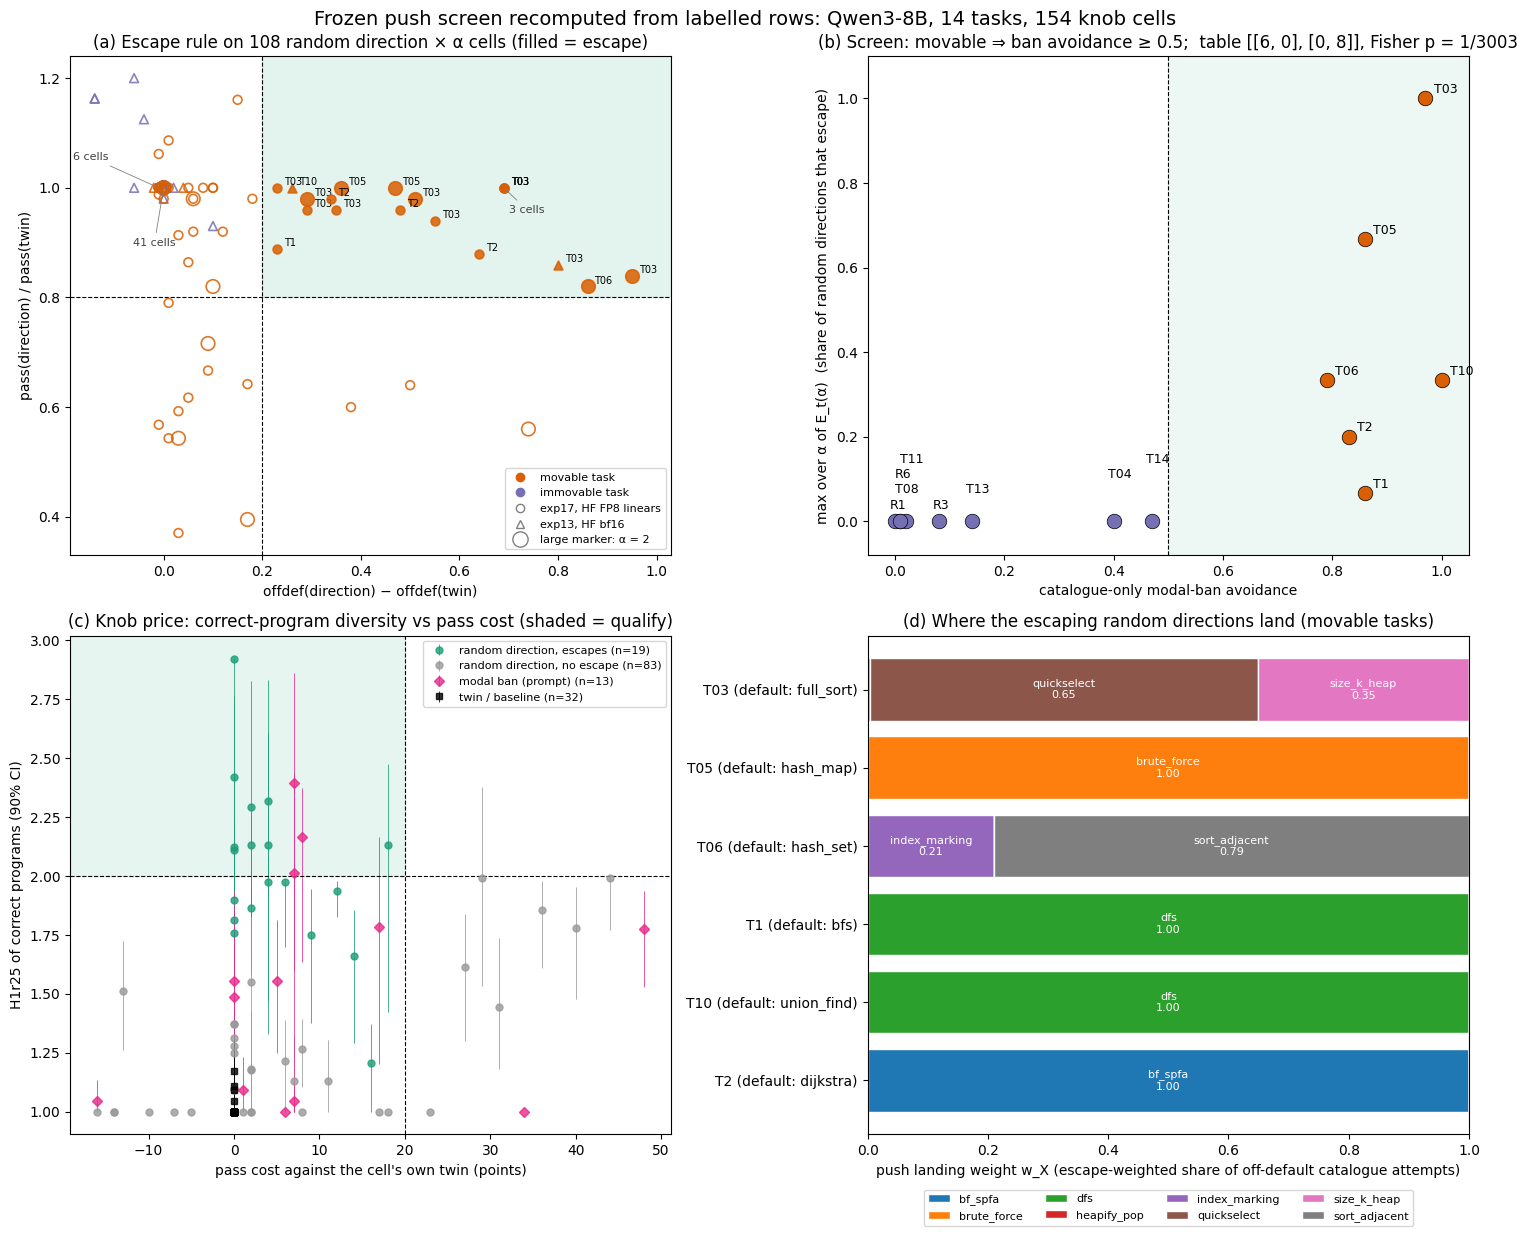

In [19]:
from matplotlib.lines import Line2D

knob = pd.read_parquet(DATA / "knob.parquet")
drows = extras["per_direction_rows"]
mov = {t: core["tasks"][t]["movable"] for t in QWEN14}
C_MOV, C_IMM, C_ESC, C_BAN = "#d95f02", "#7570b3", "#1b9e77", "#e7298a"

# ---- key results ------------------------------------------------------------------------------------------------
by_group = match_table.groupby("group", sort=False)[["matched", "of"]].sum()
key_results = pd.DataFrame([
    ("screen.json reproduced byte for byte", f"{sha == frozen} (sha256 {sha[:12]}…)"),
    ("movable tasks", ", ".join(core["movable_tasks"])),
    ("movable x (ban avoidance >= 0.5)", f"{fis['table']}  one-sided Fisher p = 1/{1 / fis['p']:.0f} (descriptive)"),
    ("tasks matching published push_screen", f"{int(per_task['matches published'].sum())}/{len(per_task)}"),
    *[(f"knob values matched: {g}", f"{int(r.matched)}/{int(r.of)}") for g, r in by_group.iterrows()],
    ("run sizes", f"N_RAREFY={N_RAREFY}, N_BOOT={N_BOOT}, N_BOOT_RAREFY={N_BOOT_RAREFY}"),
], columns=["result", "value"])
print(key_results.to_string(index=False), "\n")

fig, axes = plt.subplots(2, 2, figsize=(15, 12.5))

# ---- (a) escape rule: one marker per random direction x alpha cell ---------------------------------------------
ax = axes[0, 0]
xs, ys, stack = [], [], Counter()
for r in drows:
    od, tw = offdef(r["n_default"], r["n_attempted"]), offdef(r["twin_n_default"], r["twin_n_attempted"])
    pt = r["twin_n_passed"] / r["twin_n"]
    if od is None or tw is None or not pt:
        continue
    x, y = od - tw, (r["n_passed"] / r["n"]) / pt
    esc = escape_of(r)[0]
    c = C_MOV if mov[r["task"]] else C_IMM
    ax.scatter(x, y, s=95 if r["alpha"] == 2.0 else 40, marker="o" if r["engine"] == "hf-fp8" else "^",
               facecolors=c if esc else "none", edgecolors=c, linewidths=1.2, alpha=0.85, zorder=3)
    if esc:
        ax.annotate(r["task"], (x, y), textcoords="offset points", xytext=(5, 2), fontsize=7)
    xs.append(x)
    ys.append(y)
    stack[(round(x, 4), round(y, 4))] += 1
# identical cells (e.g. no movement at the twin's pass rate) plot as one marker: label the stacks with their size
stacks = sorted(((s, k) for s, k in stack.items() if k > 2), key=lambda sk: -sk[1])
for i, ((sx, sy), k) in enumerate(stacks):
    ax.annotate(f"{k} cells", (sx, sy), textcoords="offset points", xytext=[(-22, -42), (-62, 20), (4, -18)][i % 3],
                fontsize=8, color="0.25", arrowprops=dict(arrowstyle="-", color="0.5", lw=0.6))
x0, x1, y0, y1 = min(xs) - 0.05, max(xs) + 0.08, min(ys) - 0.04, max(ys) + 0.04
ax.fill_between([ESCAPE_MARGIN, x1], PASS_RATIO, y1, color=C_ESC, alpha=0.12, zorder=1)
ax.axvline(ESCAPE_MARGIN, color="k", ls="--", lw=0.8)
ax.axhline(PASS_RATIO, color="k", ls="--", lw=0.8)
ax.set_xlim(x0, x1)
ax.set_ylim(y0, y1)
ax.set_xlabel("offdef(direction) − offdef(twin)")
ax.set_ylabel("pass(direction) / pass(twin)")
ax.set_title(f"(a) Escape rule on {len(xs)} random direction × α cells (filled = escape)")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=C_MOV, label="movable task"),
                   Line2D([], [], marker="o", ls="", color=C_IMM, label="immovable task"),
                   Line2D([], [], marker="o", ls="", mfc="none", mec="gray", label="exp17, HF FP8 linears"),
                   Line2D([], [], marker="^", ls="", mfc="none", mec="gray", label="exp13, HF bf16"),
                   Line2D([], [], marker="o", ls="", mfc="none", mec="gray", ms=11, label="large marker: α = 2")],
          loc="lower right", fontsize=8)

# ---- (b) screen: movability against catalogue-only modal-ban avoidance -----------------------------------------
ax = axes[0, 1]
imm = sorted((t for t in QWEN14 if not mov[t]), key=lambda t: core["tasks"][t]["cat_only_ban_avoidance"])
for t in QWEN14:
    r = core["tasks"][t]
    e = max(v for v in (r["alpha_1"]["E_t"], r["alpha_2"]["E_t"]) if v is not None)
    x = r["cat_only_ban_avoidance"]
    ax.scatter(x, e, s=110, color=C_MOV if r["movable"] else C_IMM, edgecolors="k", linewidths=0.5, zorder=3)
    off = (6, 4) if r["movable"] else (-4, 9 + 11 * (imm.index(t) % 4))
    ax.annotate(t, (x, e), textcoords="offset points", xytext=off, fontsize=9)
ax.axvspan(0.5, 1.05, color=C_ESC, alpha=0.08)
ax.axvline(0.5, color="k", ls="--", lw=0.8)
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.08, 1.1)
ax.set_xlabel("catalogue-only modal-ban avoidance")
ax.set_ylabel("max over α of E_t(α)  (share of random directions that escape)")
ax.set_title(f"(b) Screen: movable ⇒ ban avoidance ≥ 0.5;  table {fis['table']}, Fisher p = 1/{1 / fis['p']:.0f}")

# ---- (c) knob price plane: H1r25 (90% CI) against pass cost ---------------------------------------------------
ax = axes[1, 0]
fin = knob[np.isfinite(knob.H1r25.astype(float))]
for sel, color, marker, lab in ((fin[(fin.family == "activation-random") & (fin.escape == True)], C_ESC, "o", "random direction, escapes"),
                                (fin[(fin.family == "activation-random") & (fin.escape == False)], "#999999", "o", "random direction, no escape"),
                                (fin[fin.family == "prompt:ban"], C_BAN, "D", "modal ban (prompt)"),
                                (fin[fin["class"] == "control"], "k", "s", "twin / baseline")):
    if not len(sel):
        continue
    ci = np.array([json.loads(v) for v in sel.H1r25_ci90], float)
    yerr = np.clip(np.vstack([sel.H1r25 - ci[:, 0], ci[:, 1] - sel.H1r25]), 0, None)
    ax.errorbar(sel.pass_cost_pts, sel.H1r25, yerr=yerr, fmt=marker, ms=5, color=color, ecolor=color, elinewidth=0.7,
                alpha=0.8, label=f"{lab} (n={len(sel)})")
xl, yl = ax.get_xlim(), ax.get_ylim()
ax.fill_between([xl[0], 20], 2, max(yl[1], 2.2), color=C_ESC, alpha=0.1)
ax.axhline(2, color="k", ls="--", lw=0.8)
ax.axvline(20, color="k", ls="--", lw=0.8)
ax.set_xlim(xl)
ax.set_ylim(yl[0], max(yl[1], 2.2))
ax.set_xlabel("pass cost against the cell's own twin (points)")
ax.set_ylabel("H1r25 of correct programs (90% CI)")
ax.set_title("(c) Knob price: correct-program diversity vs pass cost (shaded = qualify)")
ax.legend(loc="upper right", fontsize=8)

# ---- (d) push landing over escaping directions ----------------------------------------------------------------
ax = axes[1, 1]
mt = core["movable_tasks"]
mechs = sorted({m for t in mt for m in core["tasks"][t]["push_landing"]})
cmap = plt.get_cmap("tab10")
ylabels = [f"{t} (default: {QWEN_DEFAULT[t]})" for t in mt]
left = np.zeros(len(mt))
for i, m in enumerate(mechs):
    w = np.array([core["tasks"][t]["push_landing"].get(m, 0.0) for t in mt])
    ax.barh(ylabels, w, left=left, color=cmap(i % 10), edgecolor="white", label=m)
    for j in np.where(w >= 0.15)[0]:
        ax.text(left[j] + w[j] / 2, j, f"{m}\n{w[j]:.2f}", ha="center", va="center", fontsize=8, color="white")
    left += w
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("push landing weight w_X (escape-weighted share of off-default catalogue attempts)")
ax.set_title("(d) Where the escaping random directions land (movable tasks)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)

fig.suptitle("Frozen push screen recomputed from labelled rows: Qwen3-8B, 14 tasks, 154 knob cells", fontsize=14)
fig.tight_layout()
fig.savefig(WS / "figures" / "push_screen_demo.png", dpi=110, bbox_inches="tight")
plt.show()

## What this shows, and how to go further

**Reproduced here.** These hold at any run size:

- From 8,800 labelled programs, the original knob and screen code rebuilds `screen.json` byte for byte (sha256 `d6a2ca97…`).
- The movable tasks are T03, T05, T06, T1, T10 and T2, exactly the frozen C1 event set.
- Movability lines up with modal-ban avoidance ≥ 0.5 in a 6/0/0/8 table (one-sided Fisher p = 1/3003, descriptive).
- T10 escapes only on the bf16 HF engine (exp13 `rand3`). T05, T06, T1 and T2 escape only on exp17's FP8 directions, and T03 escapes on both engines.

At the original run sizes (`N_RAREFY = 1000`, `N_BOOT = 1000`, `N_BOOT_RAREFY = 200`), every knob value of the 154 cells also matches the published `tables/knob_table.csv`, including the seeded H1r25 point values and both 90% intervals.

**Reading it.** On most tasks a norm-matched random push in activation space leaves Qwen3-8B on its default. The pushes and the "do not use X" bans agree on which tasks can be moved.

| tasks | where the escaping push lands | same as the ban's main landing? |
|---|---|---|
| T1 | DFS | yes |
| T2 | Bellman-Ford/SPFA | yes |
| T03 | quickselect | yes |
| T05 | brute force | yes |
| T06 | sort-and-adjacent | no: the ban lands on index marking |
| T10 | DFS | no: the ban lands mostly on BFS |

Two cautions apply. The screen rule was read off these same data. The immovable side was tested with as few as three directions per task.

**Scaling.** Set the config cell to the original values (in its comments) and re-run from the configuration cell. On these 154 cells the knob stage then takes a few seconds.

**The full evaluation.** The other 966 knob cells, the verification targets, route landing (0b), Llama hits (0c), the 'other' audit (0d), figures (0e), rigor (0g), wording (0h), rival predictors (0j) and the independent re-derivations need the 11 dependency artifacts. Run them from the artifact folder:

```bash
uv sync --frozen && uv run eval.py --stages all   # about 1.5 min on CPU; LLM judges come from audit/judge_cache.jsonl
python3 -I audit/rederive.py                      # stdlib-only re-derivation: 29 checks, 0 mismatches
```